In [ ]:
# ============================
# STEP 1: Setup
# ============================
!pip install -q kaggle

import os, random, numpy as np, tensorflow as tf
from glob import glob
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D, Dropout, Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMAGE_SIZE = (25,25)
NUM_CLASSES = 43

MODEL_PATH = "/content/model.h5"
SAMPLES_PER_CLASS = 5

In [ ]:
# ============================
# STEP 2: Upload kaggle.json
# ============================
from google.colab import files
files.upload()

os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [ ]:
# ============================
# STEP 3: Download dataset
# ============================
!kaggle datasets download -d meowmeowmeowmeowmeow/gtsrb-german-traffic-sign --unzip

DATA_DIR = "/content/Train"  # adjust if needed

Dataset URL: https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
License(s): CC0-1.0
100% 612M/612M [00:02<00:00, 215MB/s]



In [ ]:
# ============================
# STEP 4: Data generators
# ============================
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_gen = datagen.flow_from_directory(DATA_DIR,
                                        target_size=IMAGE_SIZE,
                                        subset='training')

val_gen = datagen.flow_from_directory(DATA_DIR,
                                      target_size=IMAGE_SIZE,
                                      subset='validation')

Found 31368 images belonging to 43 classes.
Found 7841 images belonging to 43 classes.


In [ ]:
# ============================
# STEP 5: Model
# ============================
def create_model():
    model = Sequential([
        Conv2D(32,(5,5),activation='relu',input_shape=(25,25,3)),
        Conv2D(32,(5,5),activation='relu'),
        MaxPool2D(),
        Dropout(0.25),
        Conv2D(64,(3,3),activation='relu'),
        Conv2D(64,(3,3),activation='relu'),
        MaxPool2D(),
        Dropout(0.25),
        Flatten(),
        Dense(256,activation='relu'),
        Dropout(0.5),
        Dense(NUM_CLASSES,activation='softmax')
    ])
    return model

if os.path.exists(MODEL_PATH):
    print("Loading saved model...")
    model = tf.keras.models.load_model(MODEL_PATH)
else:
    print("Training model...")
    model = create_model()
    model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])
    model.fit(train_gen, epochs=40, validation_data=val_gen)
    model.save(MODEL_PATH)

In [ ]:
# ============================
# STEP 6: GA ATTACK
# ============================

def fitness(model, image, perturb, target):
    adv = np.clip(image + perturb, 0, 1)
    pred = model.predict(adv[None,...], verbose=0)[0]
    return pred[target]

def evolutionary_attack(model, image, target):
    population = [np.random.uniform(-0.1,0.1,image.shape) for _ in range(100)]

    best = None
    best_score = -1

    for gen in range(100):
        scores = [fitness(model,image,p,target) for p in population]

        new_pop = []
        for _ in range(len(population)):
            i,j = np.random.randint(0,len(population),2)
            parent = population[i] if scores[i]>scores[j] else population[j]

            child = parent.copy()

            if random.random()<0.5:
                child += np.random.normal(0,0.02,image.shape)

            new_pop.append(child)

        population = new_pop

        idx = np.argmax(scores)
        if scores[idx] > best_score:
            best_score = scores[idx]
            best = population[idx]

    adv = np.clip(image + best,0,1)
    return adv, best_score

Source class index: 23
Target class index: 38
Image 1 (00003_00032_00010.png) | L2 Distance: 4.329298


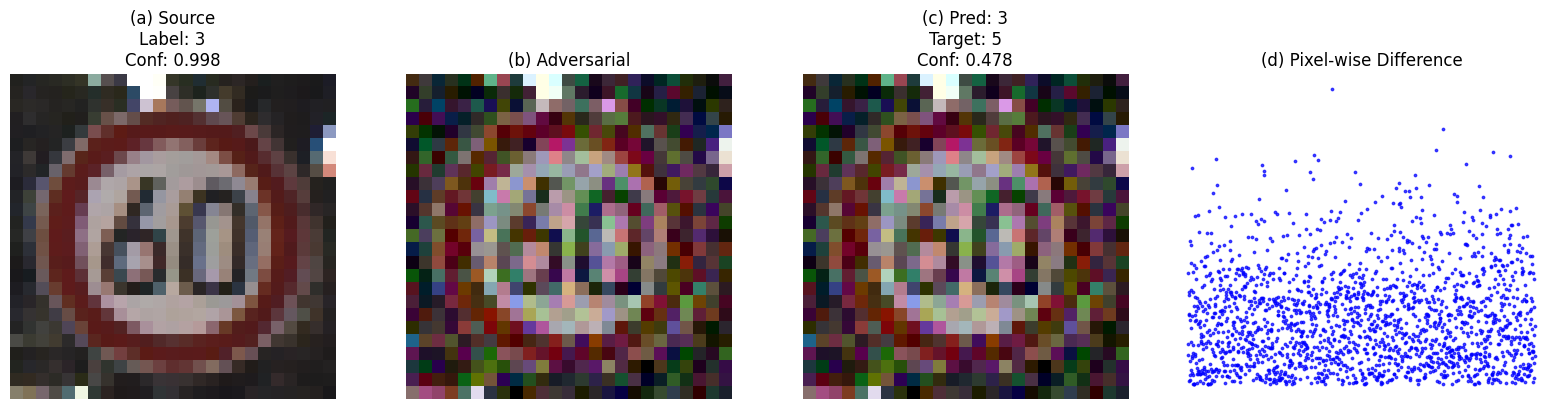

Image 2 (00003_00031_00026.png) | L2 Distance: 4.122152


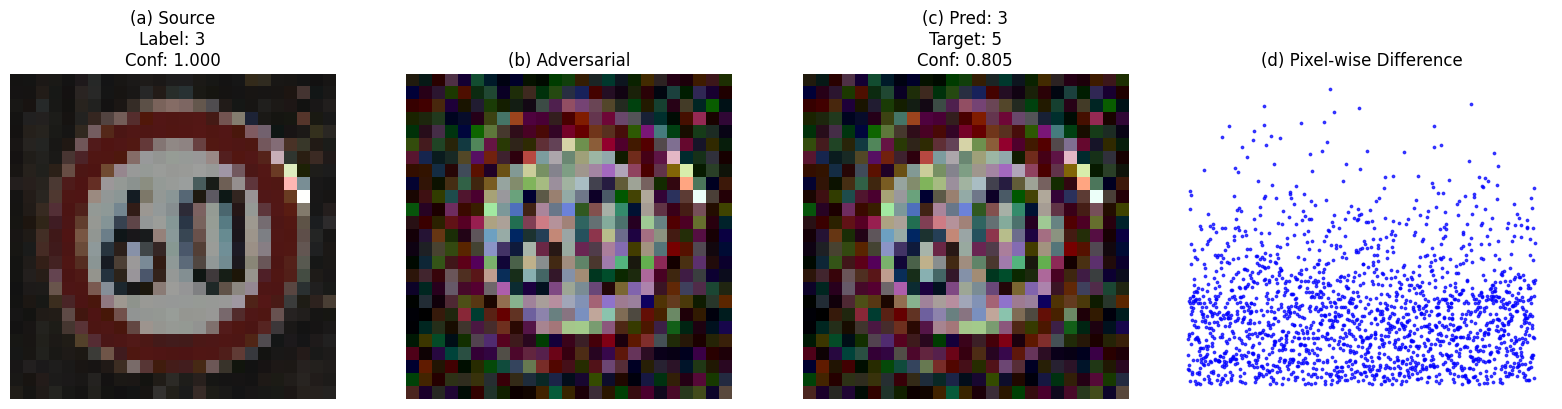

Image 3 (00003_00042_00002.png) | L2 Distance: 3.065647


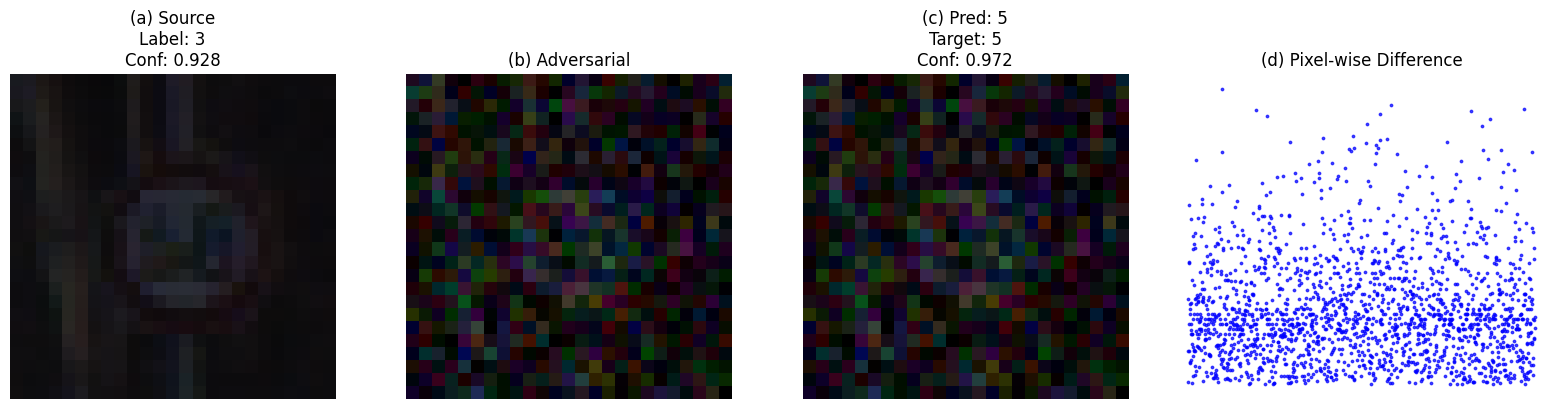

Image 4 (00003_00032_00011.png) | L2 Distance: 4.592799


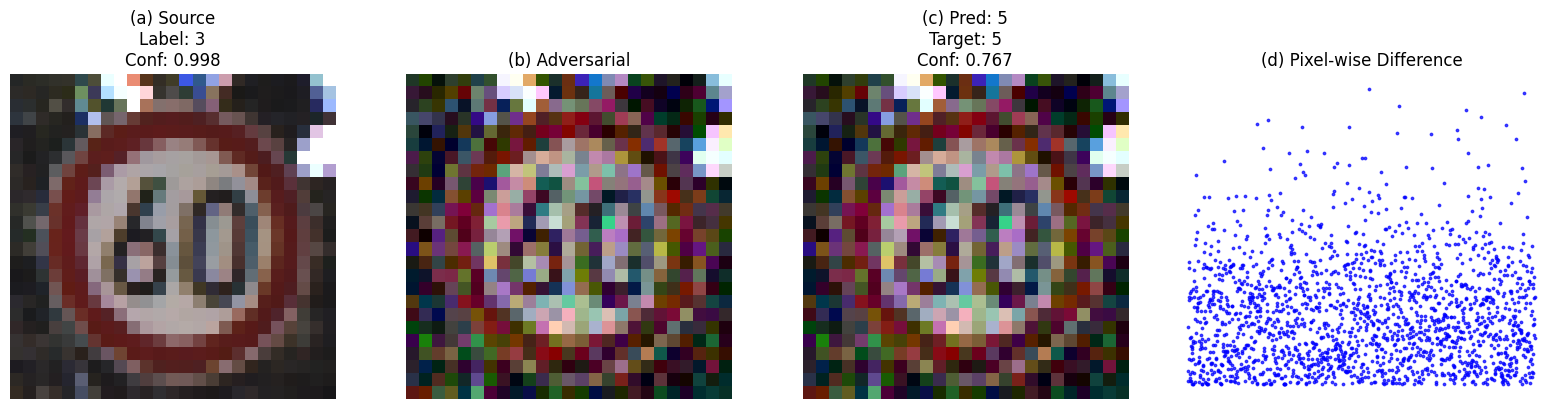

Image 5 (00003_00016_00027.png) | L2 Distance: 3.439803


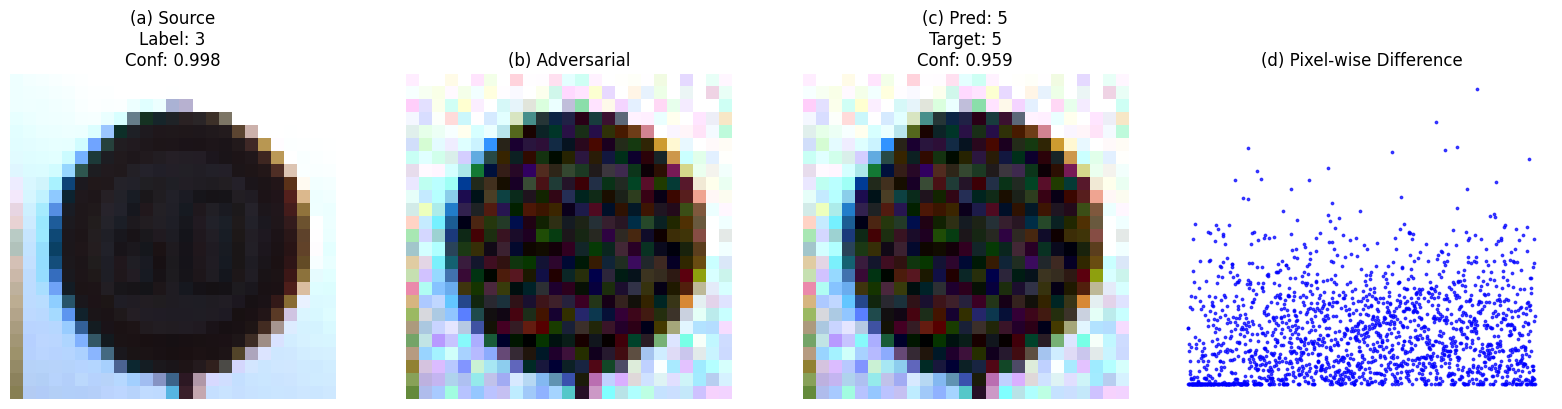


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 3
Success Rate: 60.00%
Mean L2: 3.9099
Std L2: 0.5694


In [ ]:
# ============================
# REPORTED IN PAPER: In Table Number 15, 17 and Supplementary information
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['3']
TARGET_CLASS = class_indices['5']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('3')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 14
Target class index: 17
Image 1 (00021_00005_00006.png) | L2 Distance: 4.031591


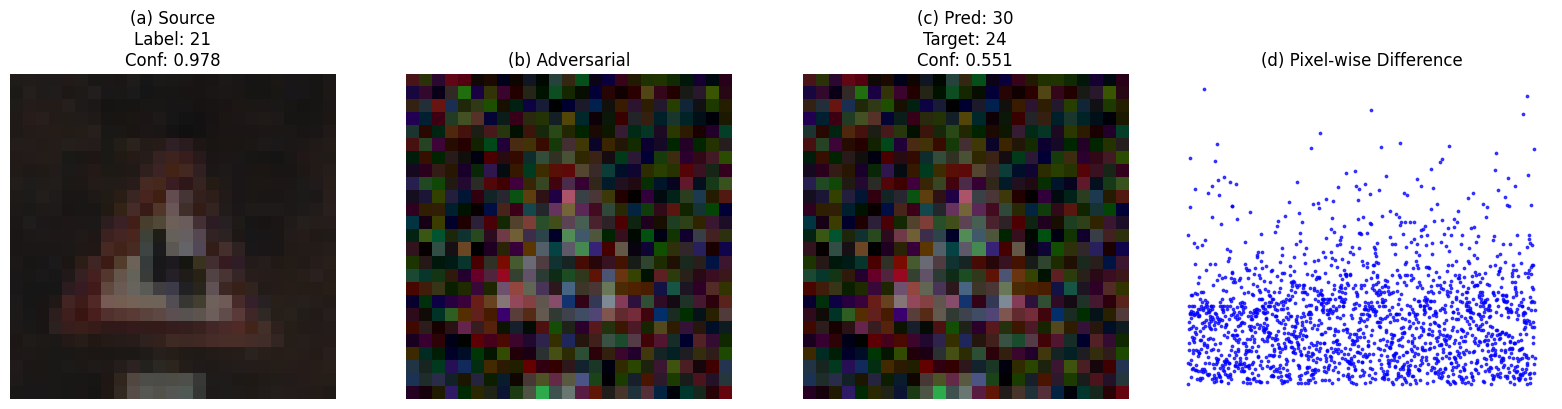

Image 2 (00021_00010_00012.png) | L2 Distance: 4.232790


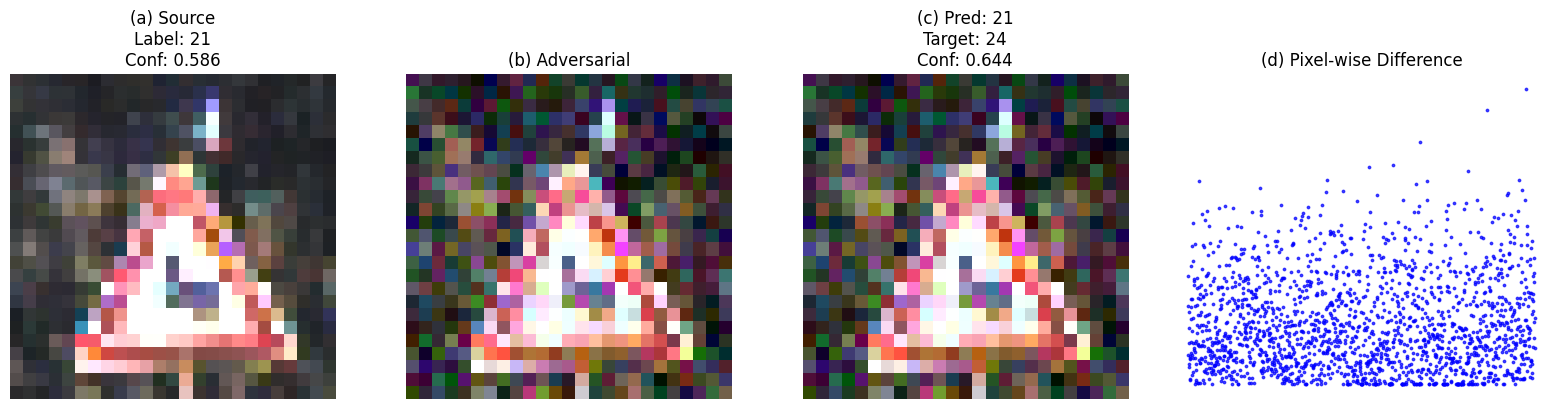

Image 3 (00021_00008_00027.png) | L2 Distance: 3.237228


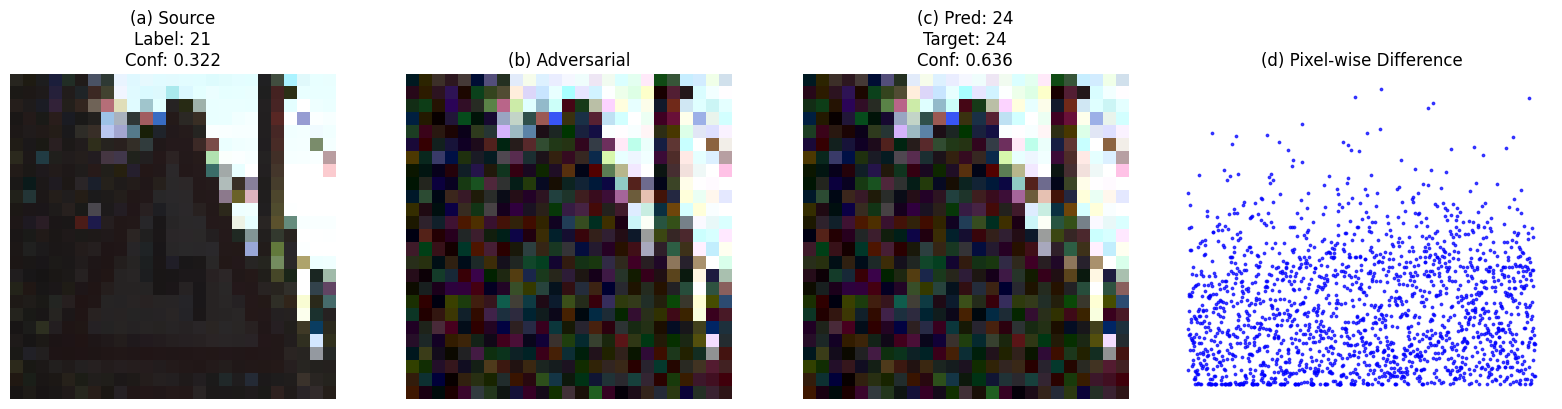

Image 4 (00021_00002_00005.png) | L2 Distance: 4.570315


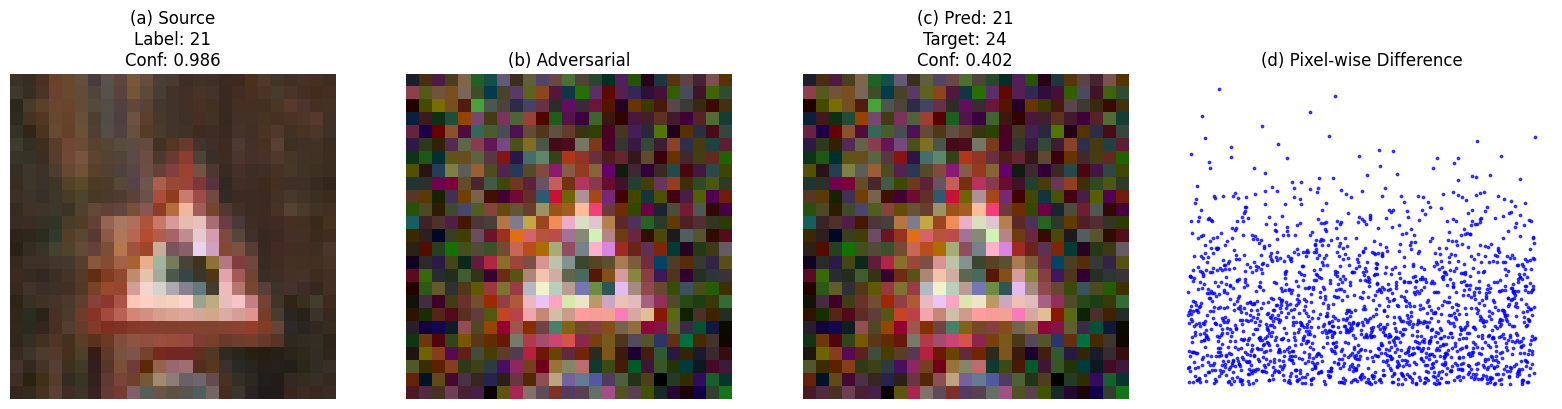

Image 5 (00021_00003_00013.png) | L2 Distance: 4.456490


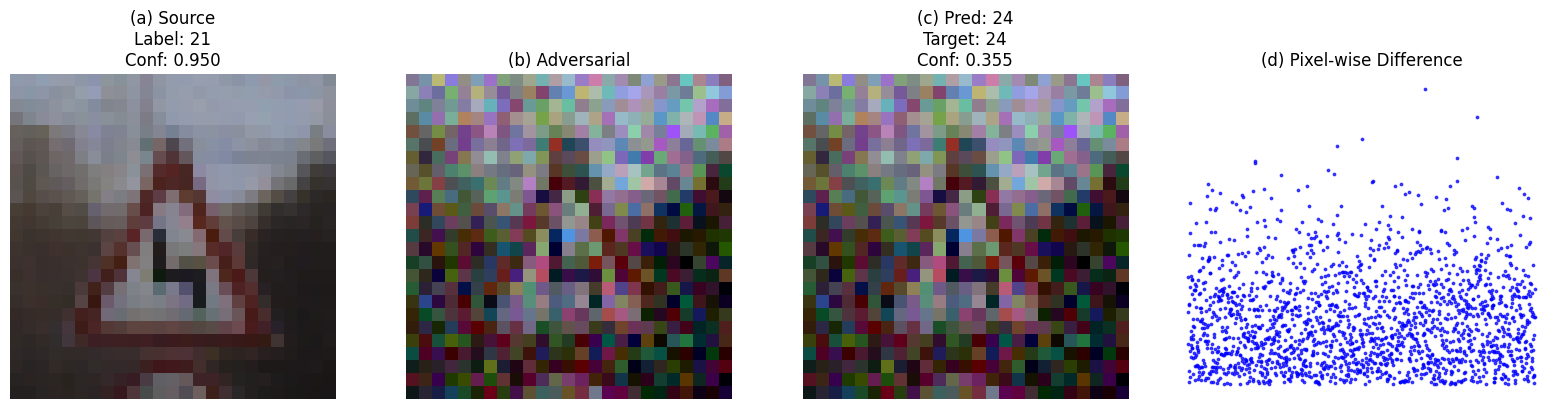


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 2
Success Rate: 40.00%
Mean L2: 4.1057
Std L2: 0.4722


In [ ]:
# ============================
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['21']
TARGET_CLASS = class_indices['24']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('21')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 1
Target class index: 38
Image 1 (00001_00070_00016.png) | L2 Distance: 4.526695


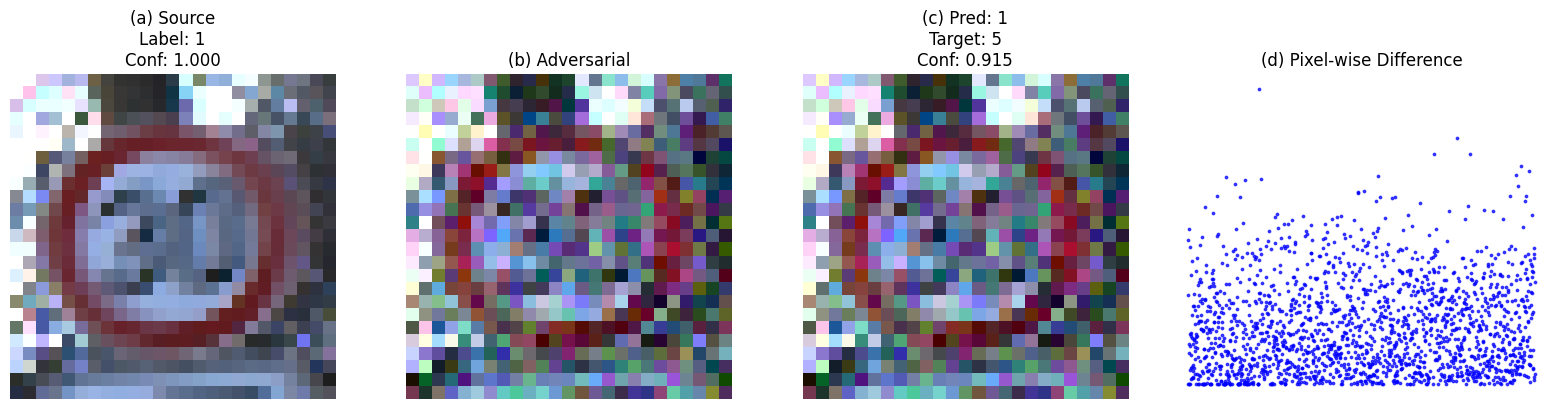

Image 2 (00001_00070_00015.png) | L2 Distance: 4.314627


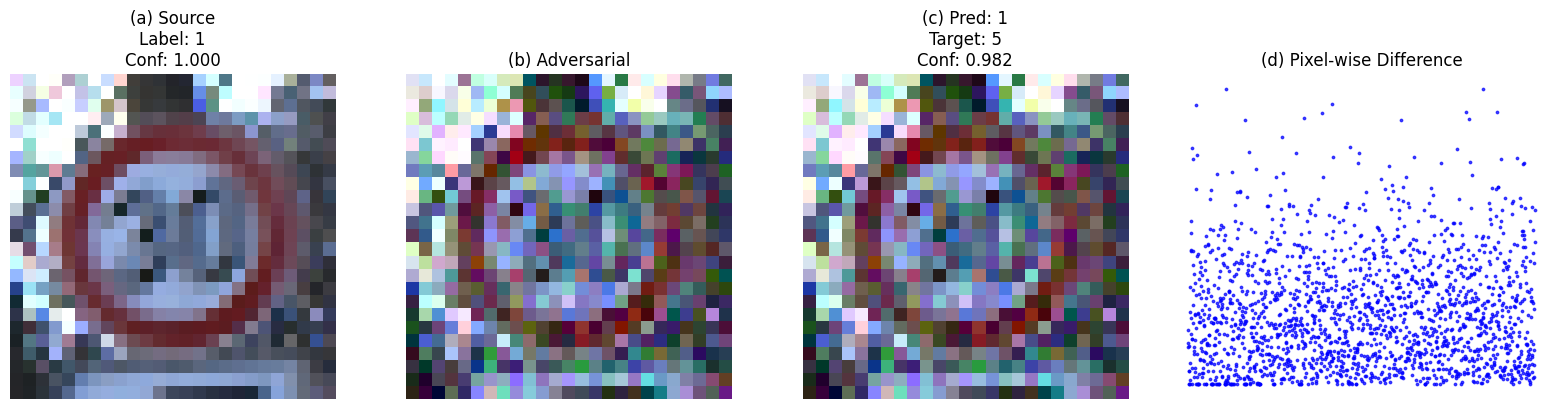

Image 3 (00001_00018_00014.png) | L2 Distance: 4.302325


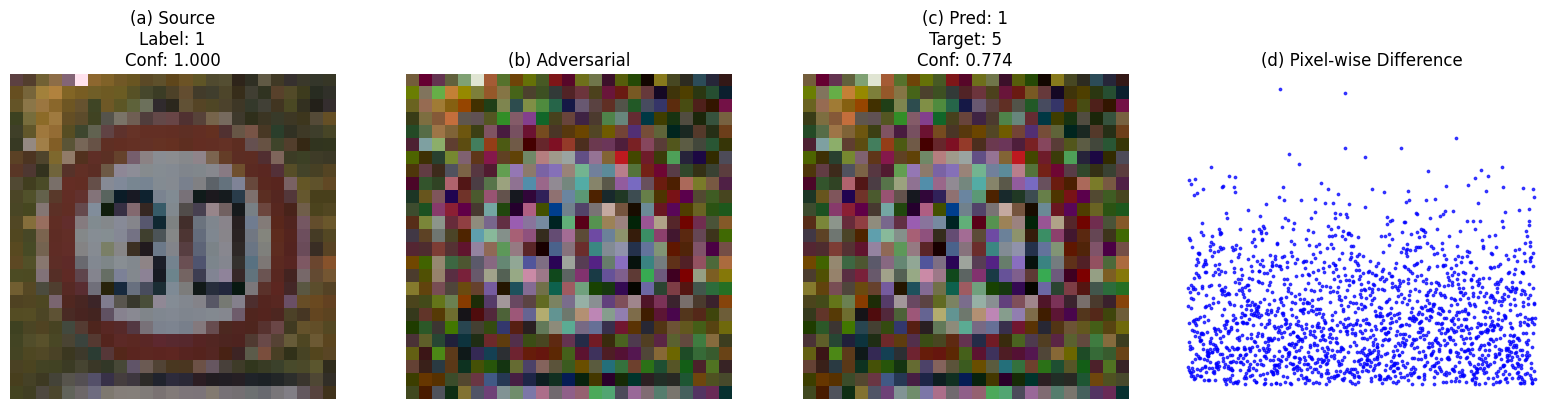

Image 4 (00001_00014_00029.png) | L2 Distance: 4.479664


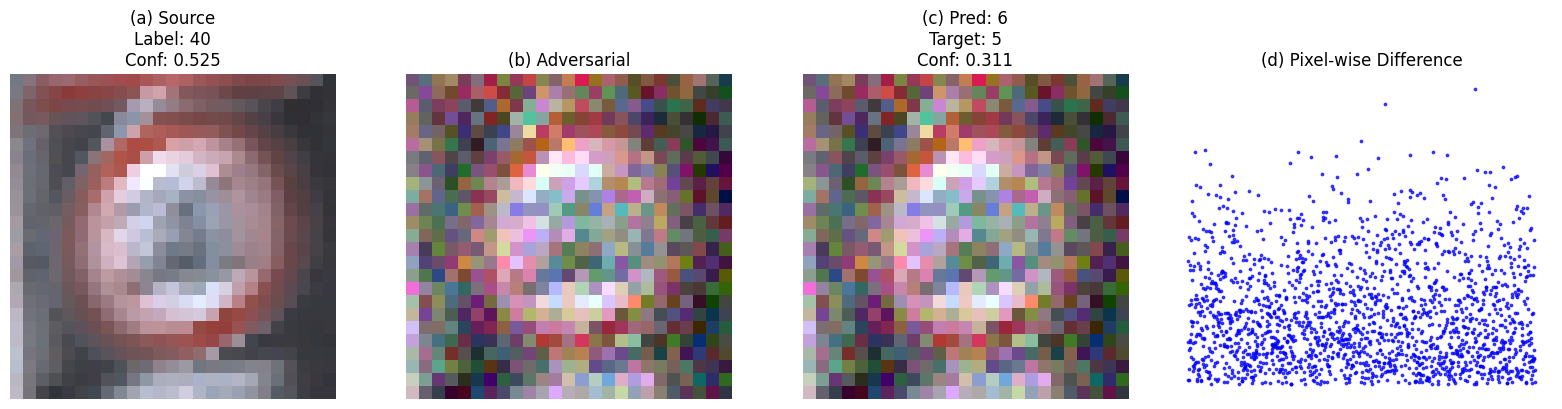

Image 5 (00001_00015_00022.png) | L2 Distance: 4.658408


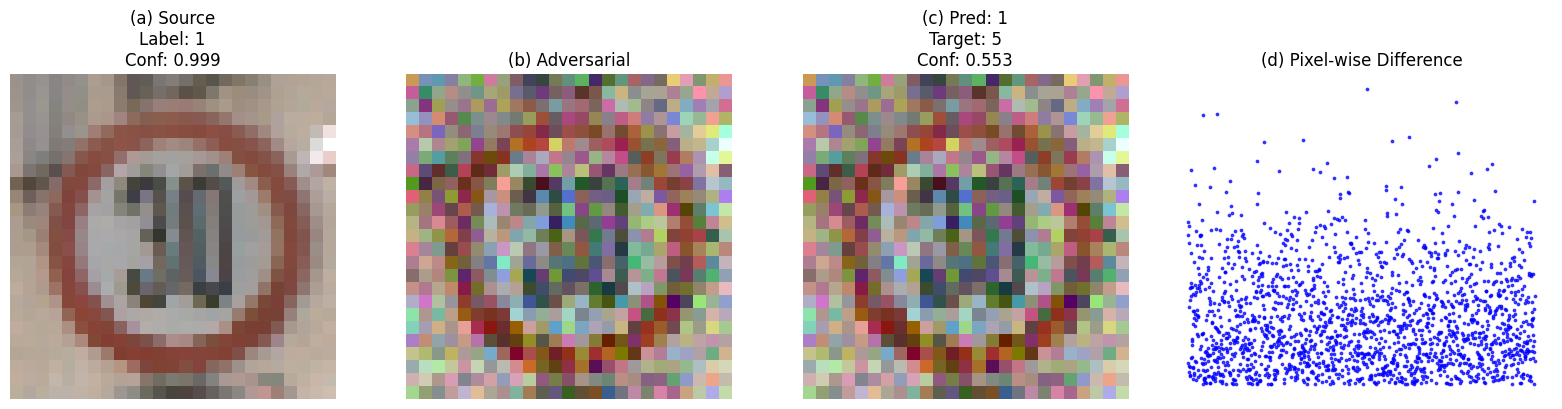


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 0
Success Rate: 0.00%
Mean L2: 4.4563
Std L2: 0.1343


In [ ]:
# ============================
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['1']
TARGET_CLASS = class_indices['5']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('1')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

In [ ]:
# ============================
# STEP 8: FINAL RESULTS
# ============================

total = len(images)
success_rate = success/total * 100

print("\n===== RESULTS =====")
print("Total images:", total)
print("Success:", success)
print("Success rate:", success_rate)

print("Mean L2:", np.mean(l2_list))
print("Std L2:", np.std(l2_list))


===== RESULTS =====
Total images: 5
Success: 0
Success rate: 0.0
Mean L2: 4.456343820453901
Std L2: 0.13425980614098323


Source class index: 20
Target class index: 21
Image 1 (00027_00004_00000.png) | L2 Distance: 4.011500


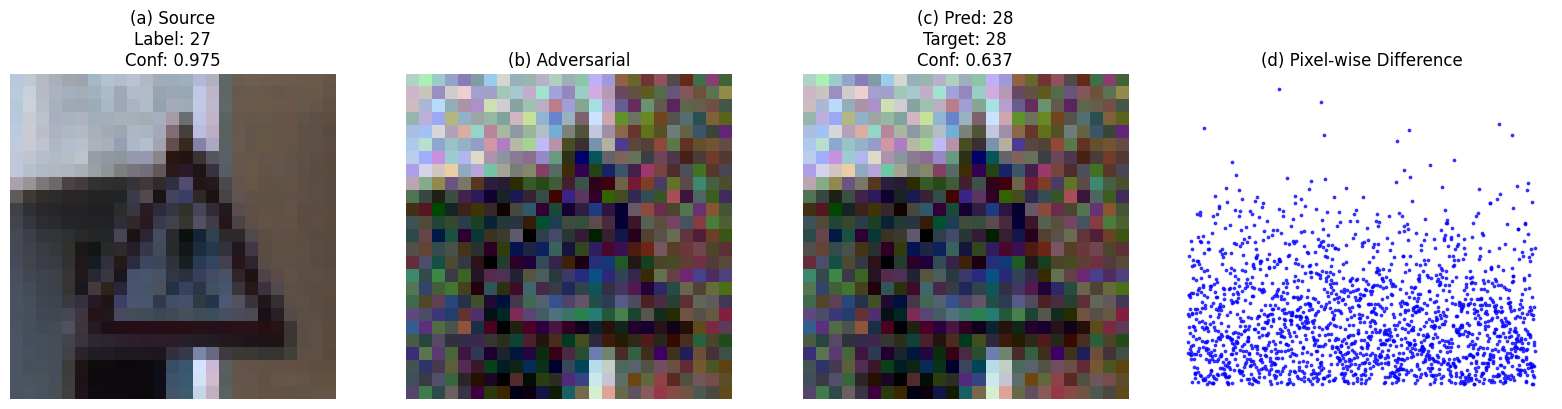

Image 2 (00027_00003_00019.png) | L2 Distance: 4.328251


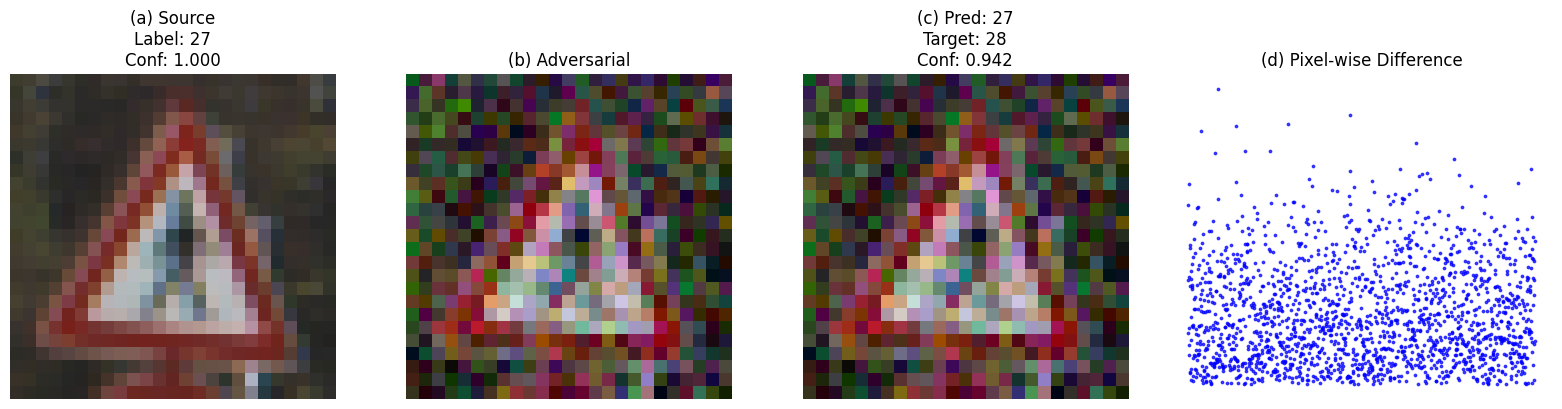

Image 3 (00027_00003_00008.png) | L2 Distance: 4.636876


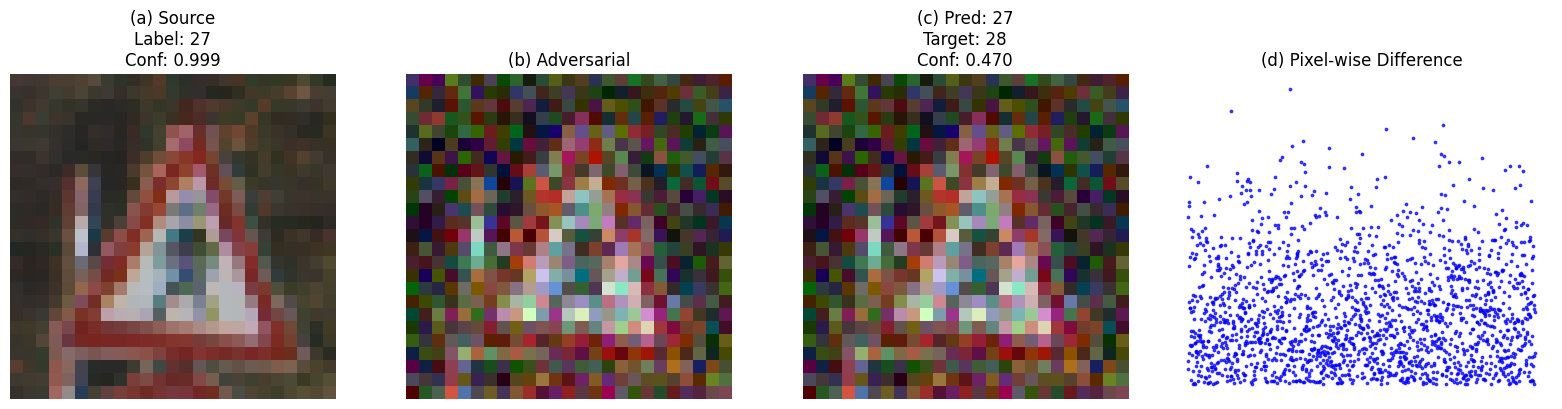

Image 4 (00027_00007_00007.png) | L2 Distance: 4.520846


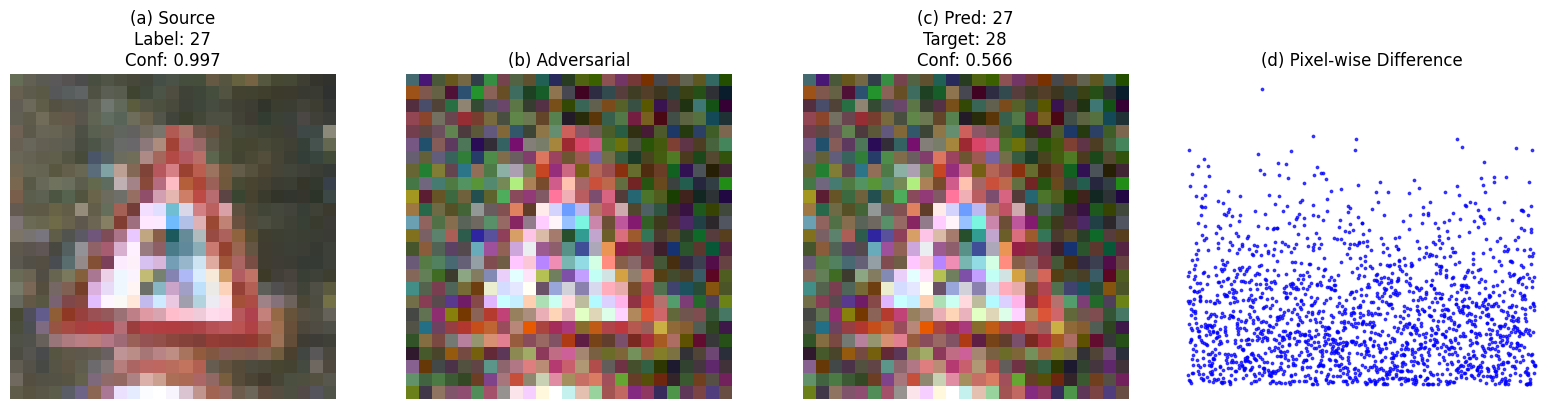

Image 5 (00027_00003_00018.png) | L2 Distance: 4.321015


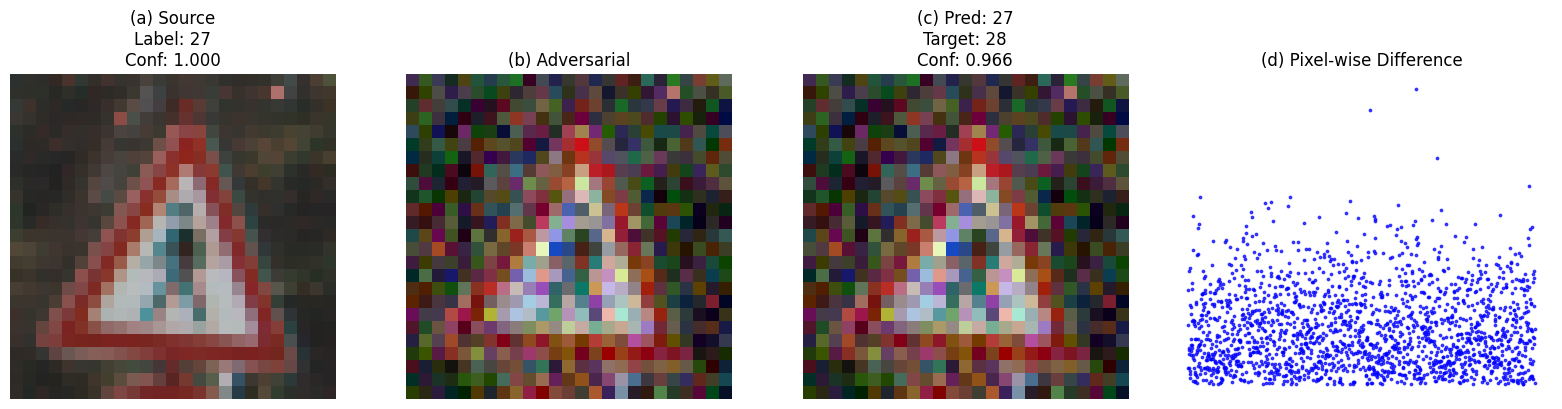


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 1
Success Rate: 20.00%
Mean L2: 4.3637
Std L2: 0.2128


In [ ]:
# ============================
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['27']
TARGET_CLASS = class_indices['28']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('27')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 41
Target class index: 40
Image 1 (00008_00003_00018.png) | L2 Distance: 3.188760


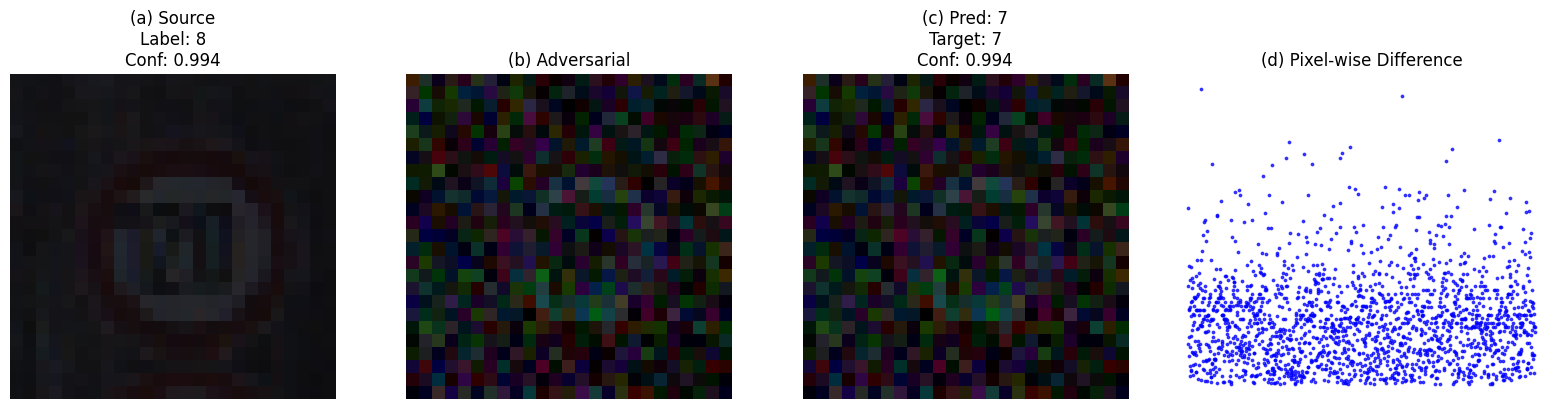

Image 2 (00008_00036_00012.png) | L2 Distance: 3.756678


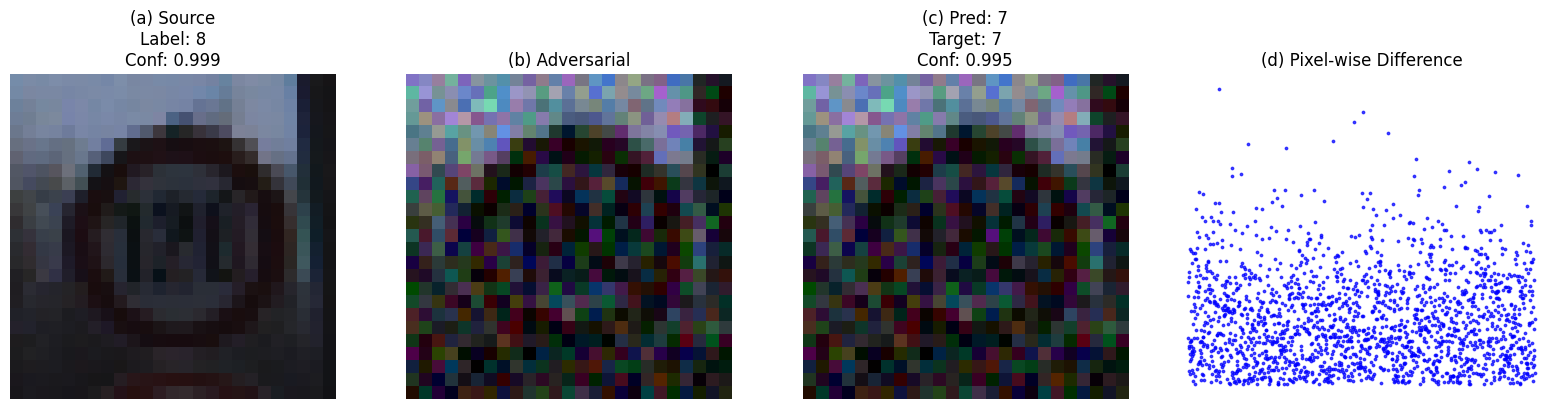

Image 3 (00008_00010_00024.png) | L2 Distance: 3.793468


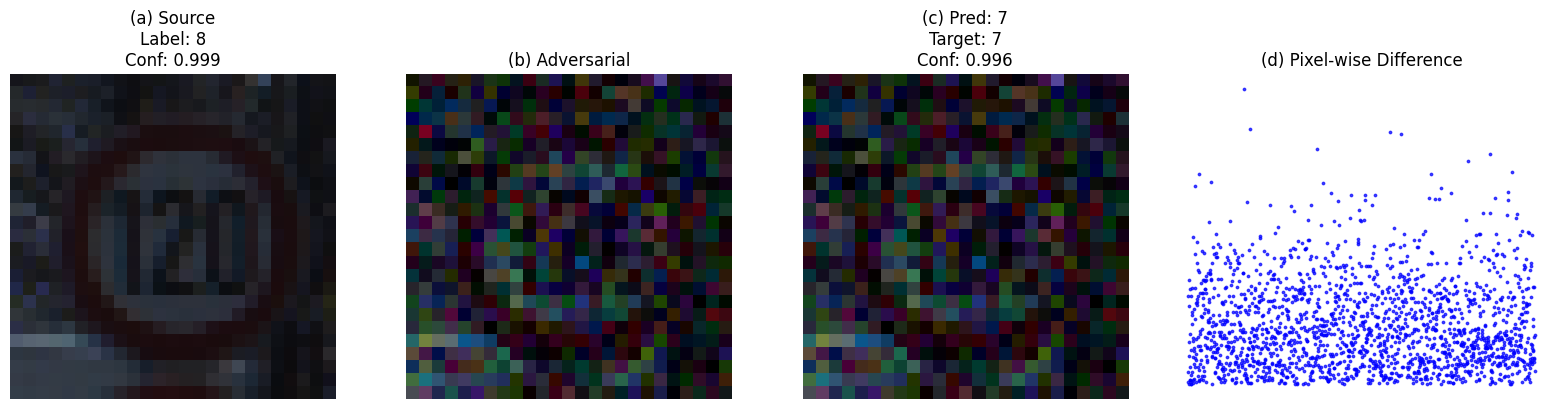

Image 4 (00008_00030_00018.png) | L2 Distance: 3.373096


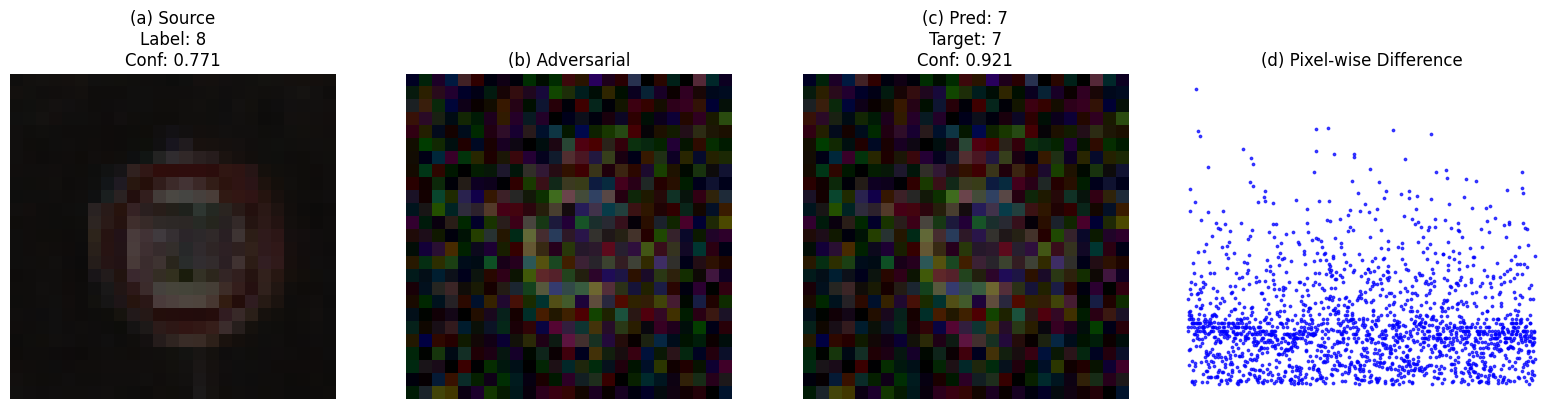

Image 5 (00008_00027_00003.png) | L2 Distance: 4.258090


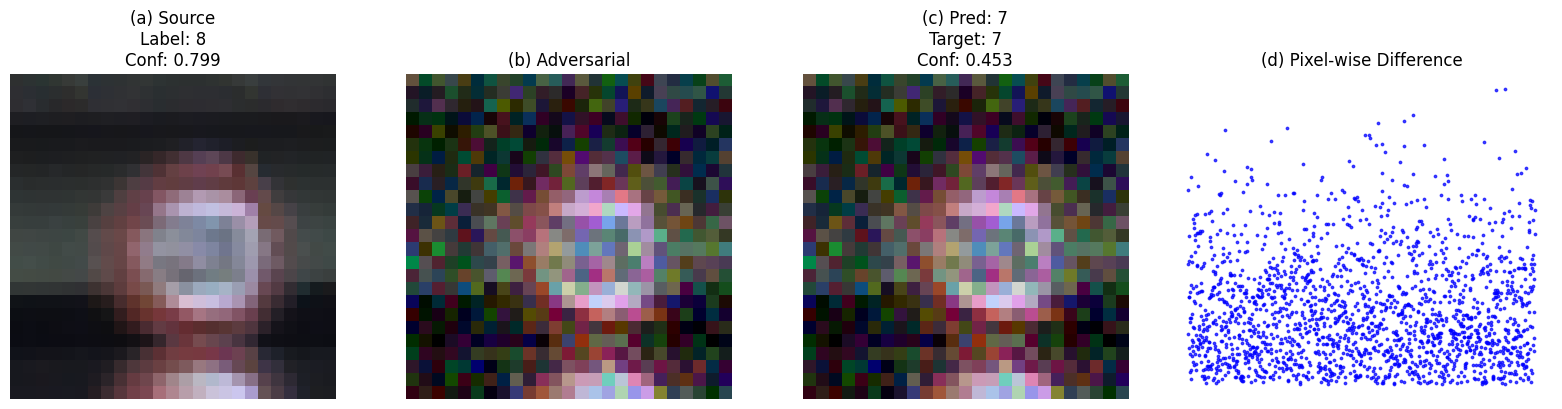


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 5
Success Rate: 100.00%
Mean L2: 3.6740
Std L2: 0.3710


In [ ]:
# ============================
# REPORTED IN PAPER: In Table Number 15, 17 and Supplementary information
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['8']
TARGET_CLASS = class_indices['7']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('8')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 42
Target class index: 2
Image 1 (00009_00029_00029.png) | L2 Distance: 4.420286


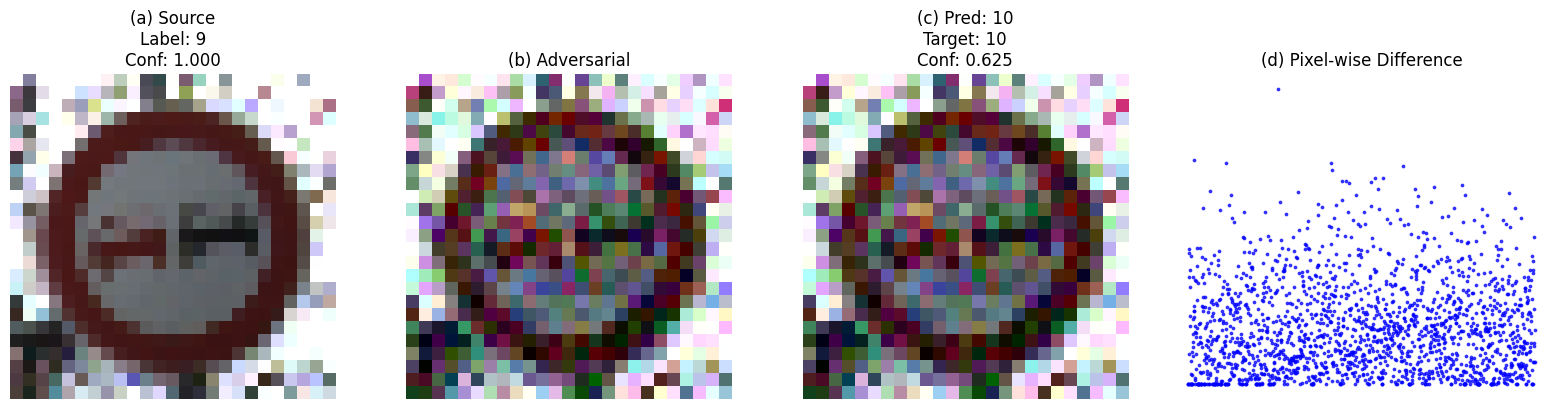

Image 2 (00009_00029_00004.png) | L2 Distance: 4.310967


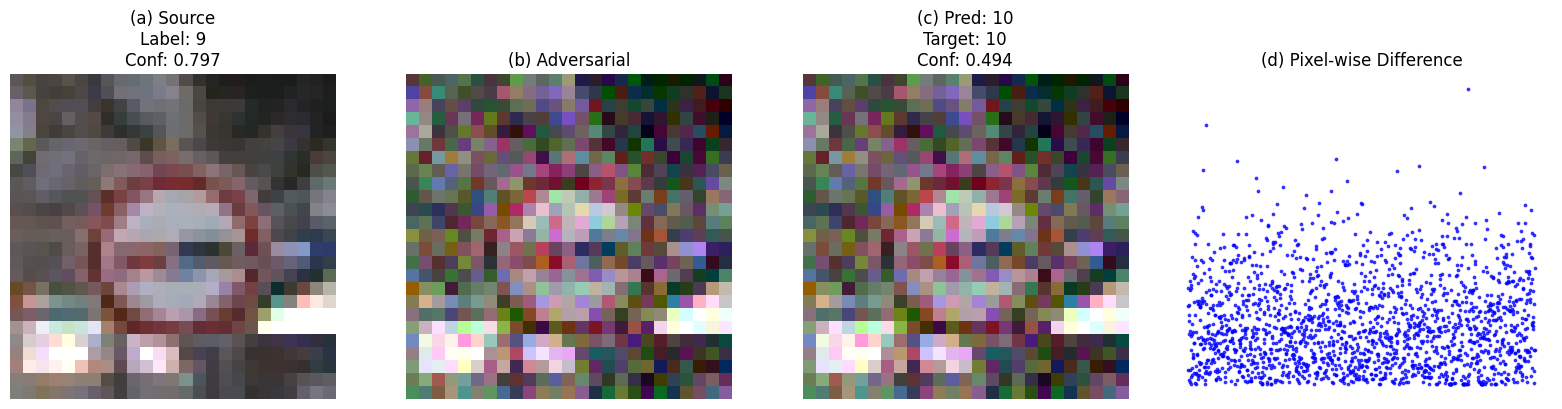

Image 3 (00009_00034_00012.png) | L2 Distance: 4.029710


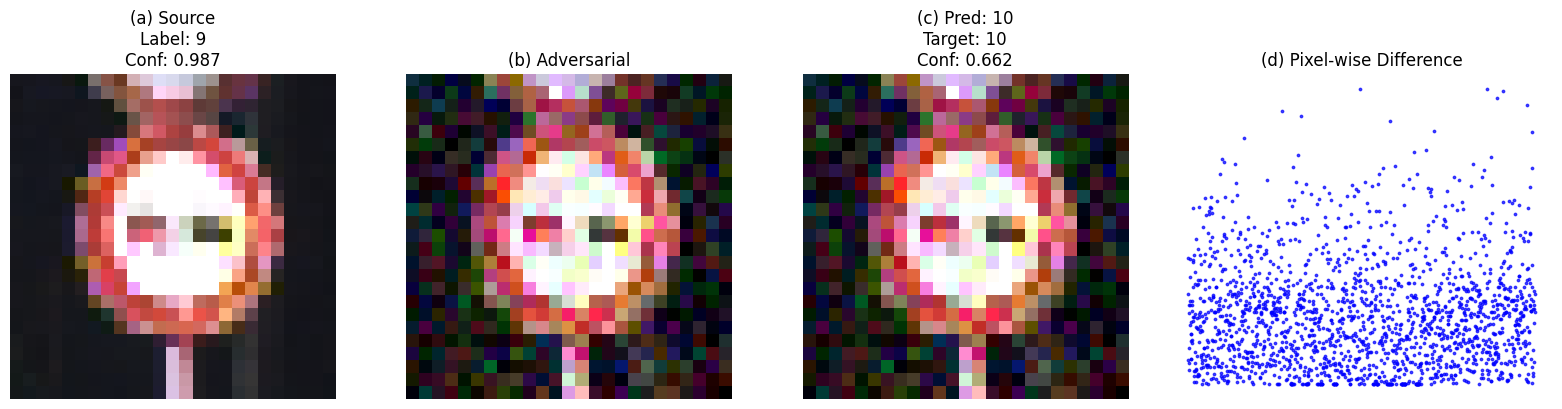

Image 4 (00009_00013_00018.png) | L2 Distance: 4.059149


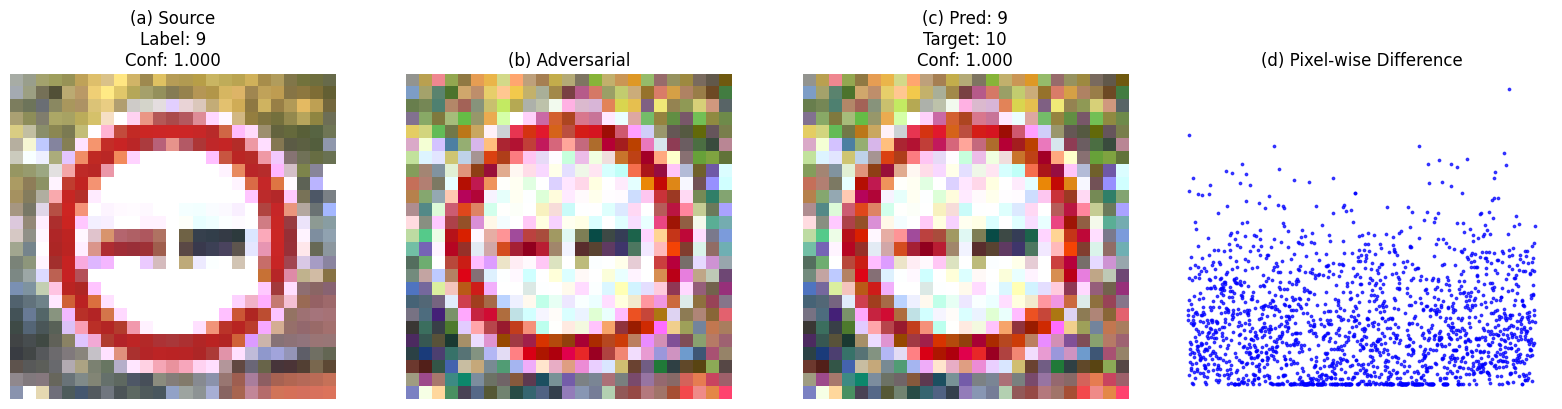

Image 5 (00009_00037_00005.png) | L2 Distance: 3.775527


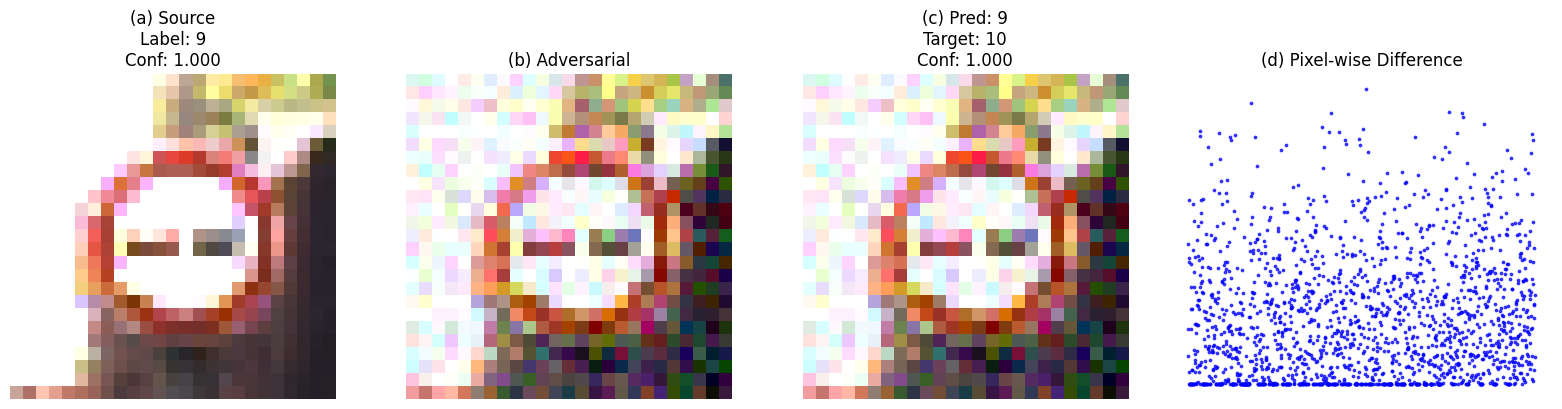


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 3
Success Rate: 60.00%
Mean L2: 4.1191
Std L2: 0.2268


In [ ]:
# ============================
# REPORTED IN PAPER: In Table Number 15, 17 and Supplementary information
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING (FIXED)
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['9']
TARGET_CLASS = class_indices['10']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('9')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 36
Target class index: 37
Image 1 (00041_00004_00024.png) | L2 Distance: 4.369760


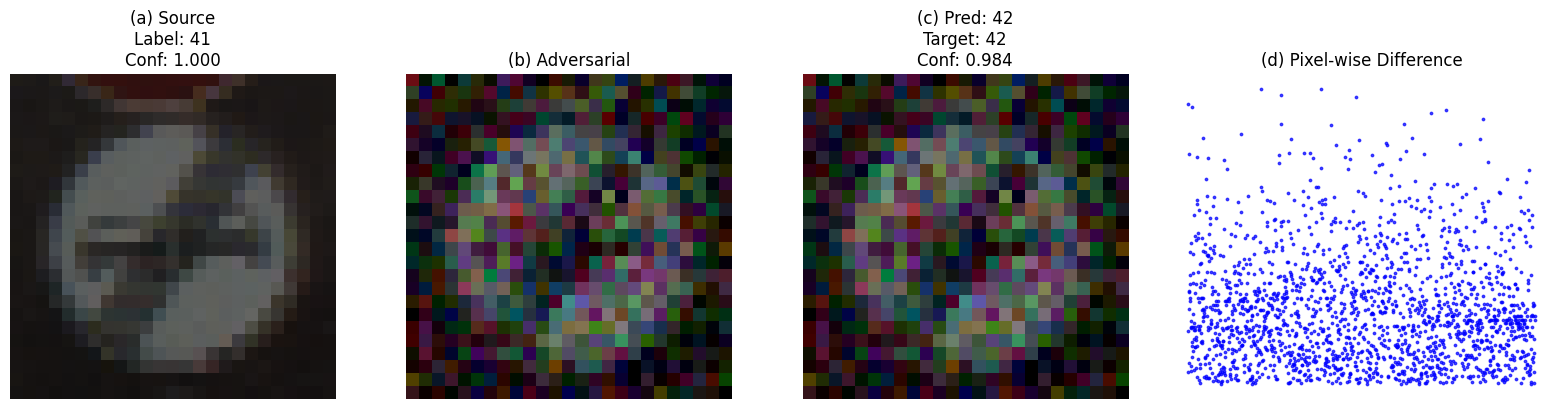

Image 2 (00041_00004_00021.png) | L2 Distance: 3.782712


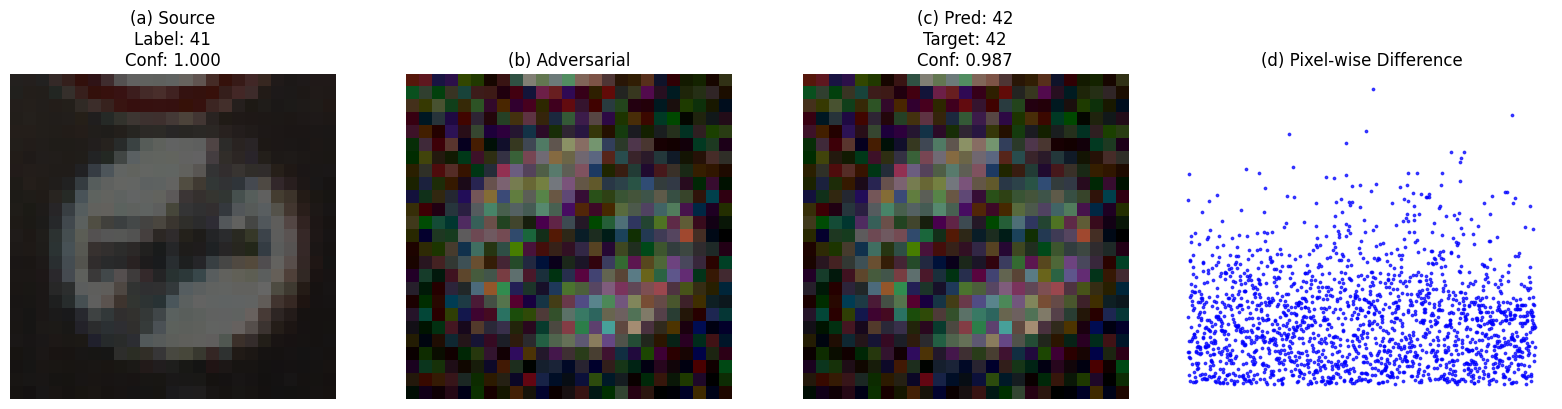

Image 3 (00041_00007_00005.png) | L2 Distance: 3.776758


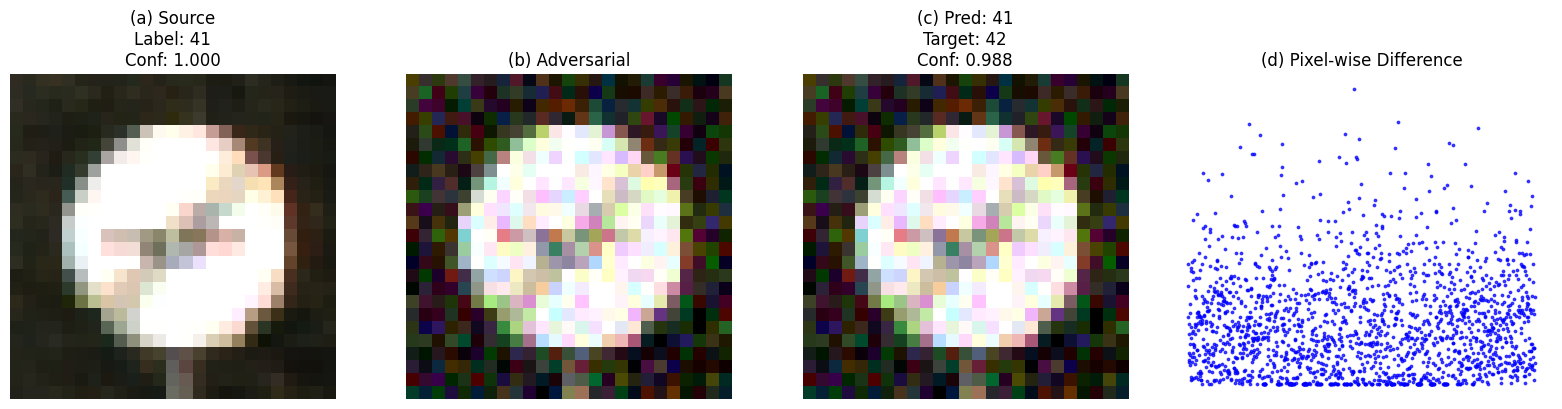

Image 4 (00041_00001_00028.png) | L2 Distance: 4.198528


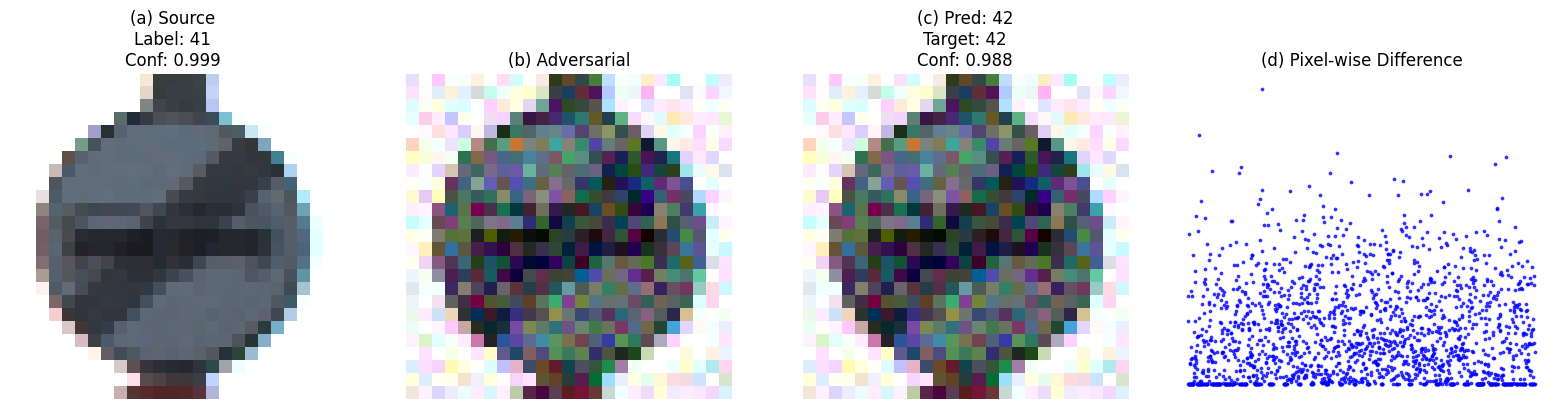

Image 5 (00041_00003_00000.png) | L2 Distance: 4.163550


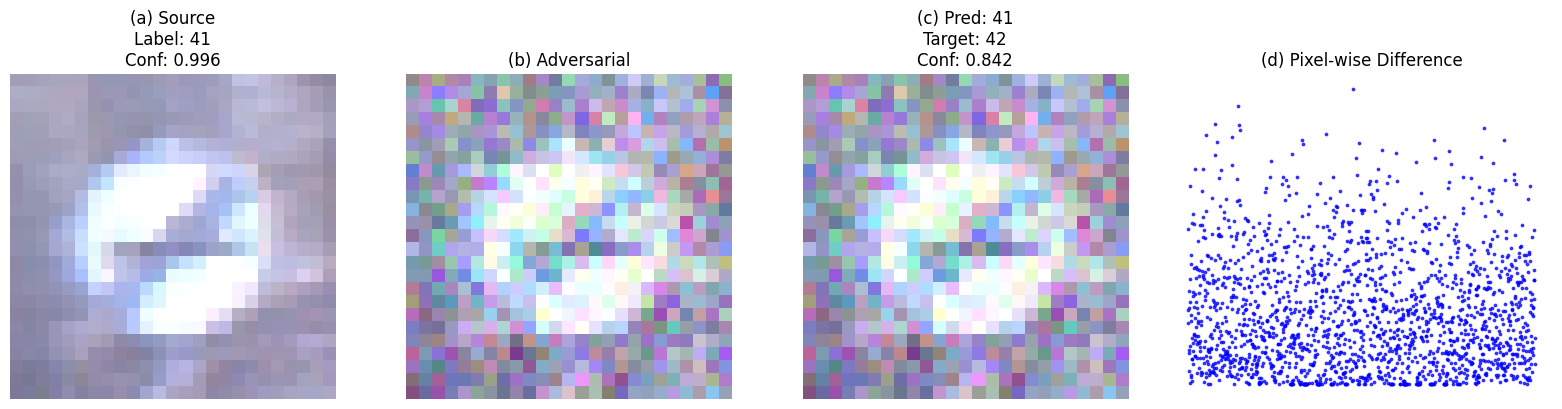


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 3
Success Rate: 60.00%
Mean L2: 4.0583
Std L2: 0.2379


In [ ]:
# ============================
# REPORTED IN PAPER: In Table Number 15, 17 and Supplementary information
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING (FIXED)
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['41']
TARGET_CLASS = class_indices['42']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('41')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 3
Target class index: 10
Image 1 (00011_00027_00027.png) | L2 Distance: 4.440131


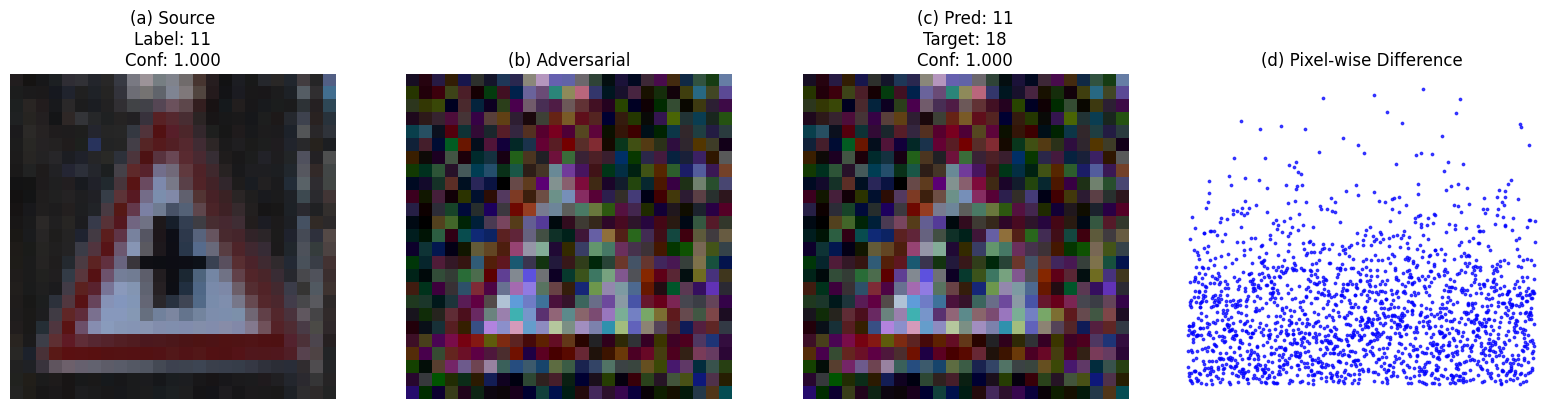

Image 2 (00011_00037_00022.png) | L2 Distance: 4.248875


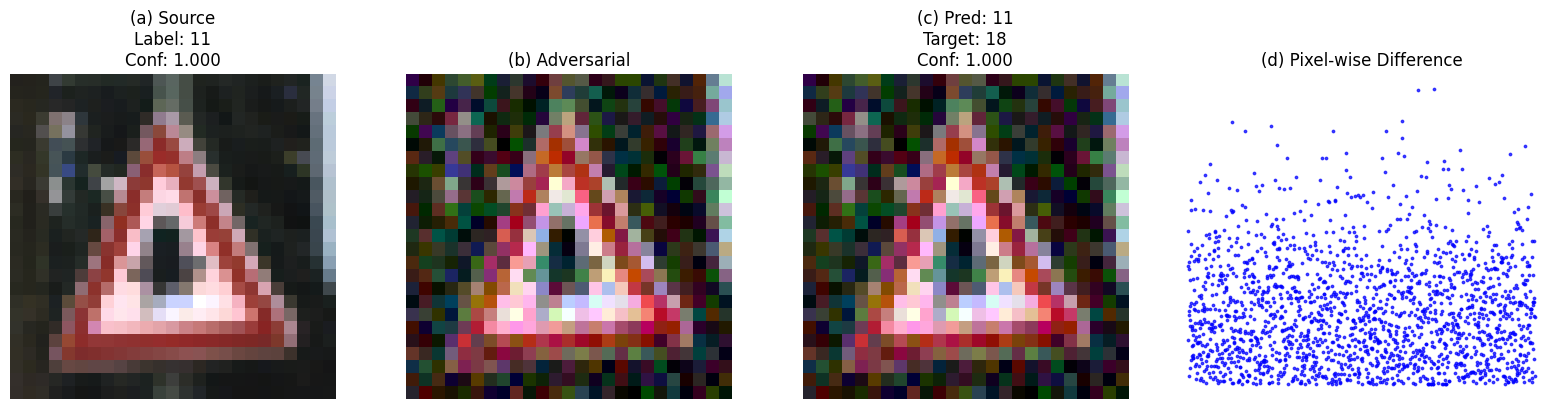

Image 3 (00011_00022_00013.png) | L2 Distance: 3.709259


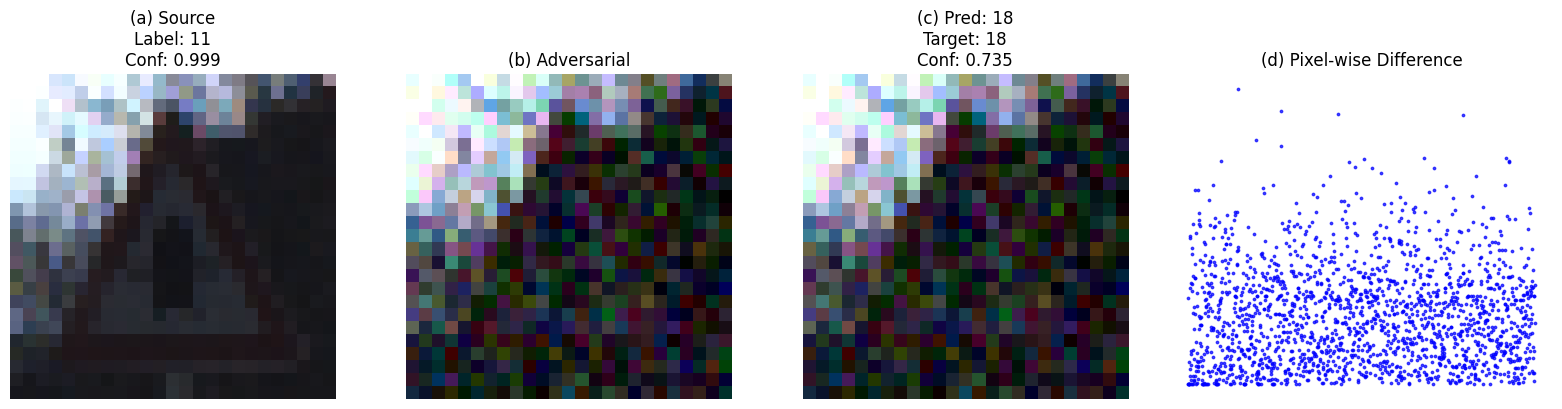

Image 4 (00011_00019_00017.png) | L2 Distance: 3.961150


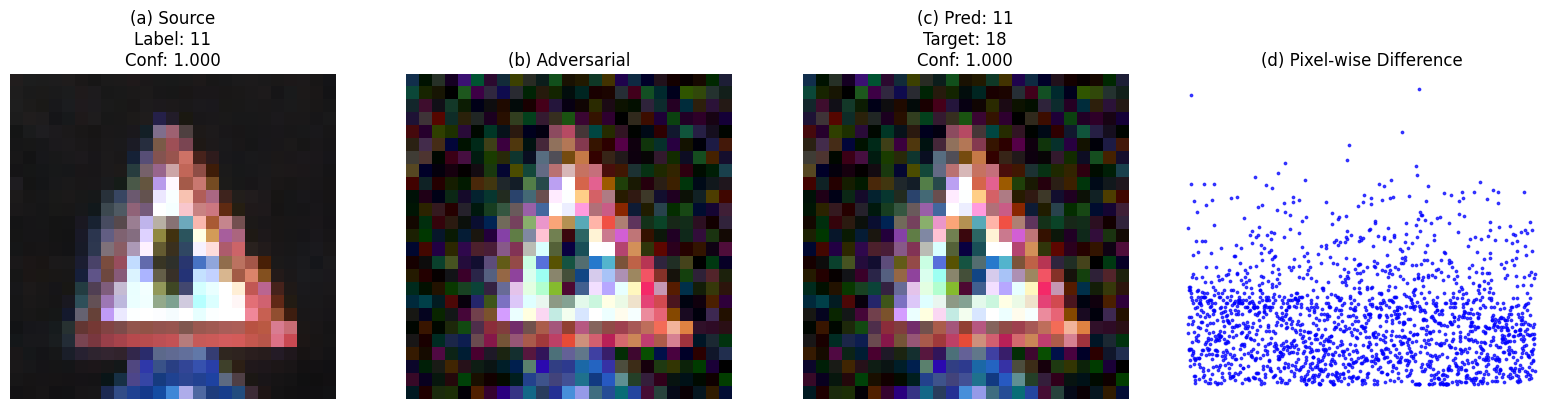

Image 5 (00011_00043_00023.png) | L2 Distance: 4.524585


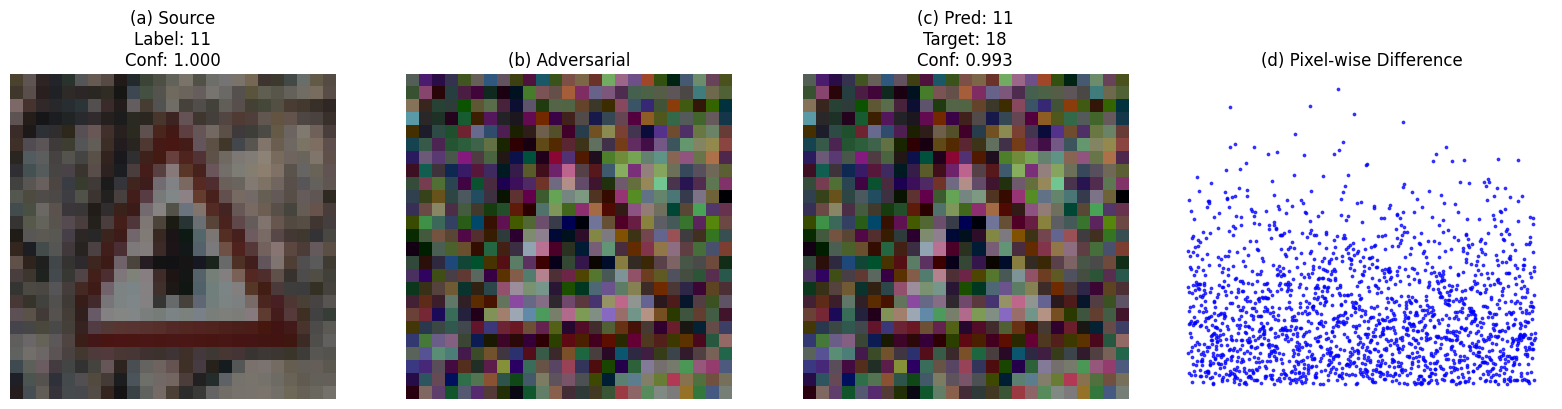


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 1
Success Rate: 20.00%
Mean L2: 4.1768
Std L2: 0.3035


In [ ]:
# ============================
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['11']
TARGET_CLASS = class_indices['18']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('11')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 12
Target class index: 23
Image 1 (00002_00071_00021.png) | L2 Distance: 4.153996


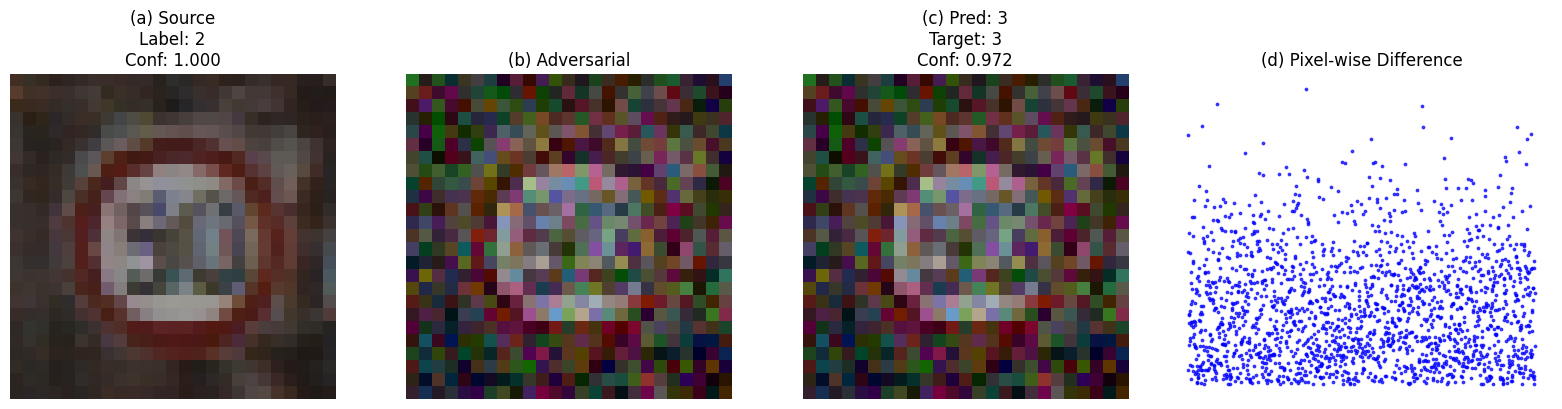

Image 2 (00002_00041_00002.png) | L2 Distance: 4.154326


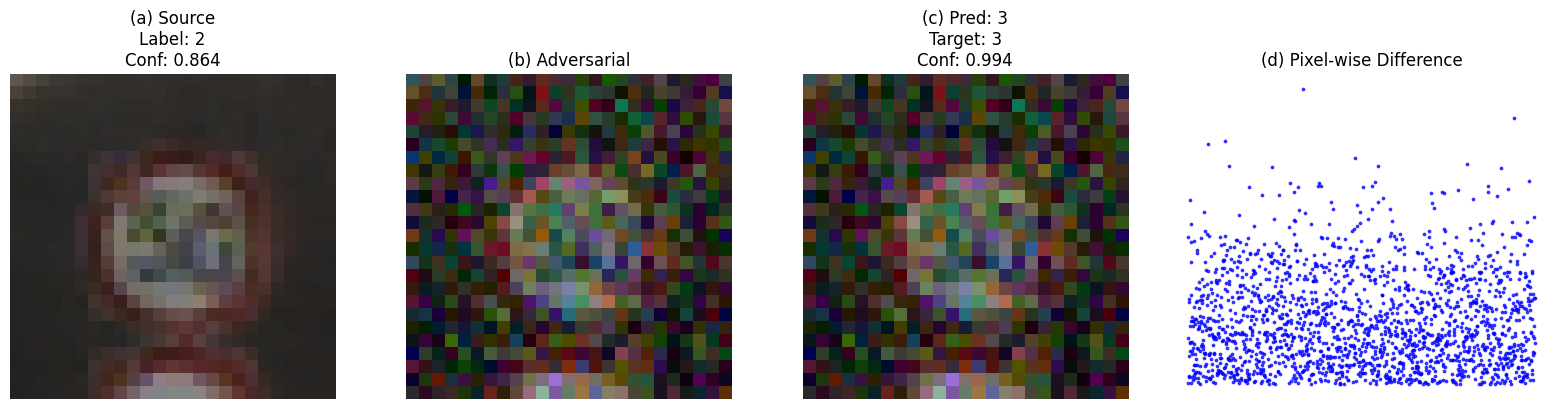

Image 3 (00002_00057_00002.png) | L2 Distance: 4.134720


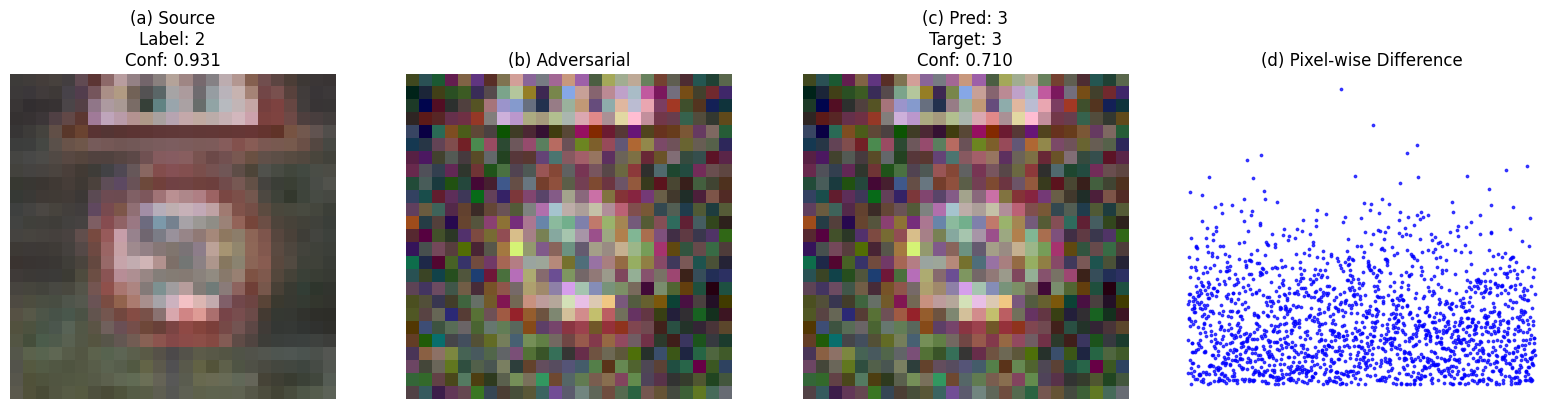

Image 4 (00002_00030_00002.png) | L2 Distance: 4.512811


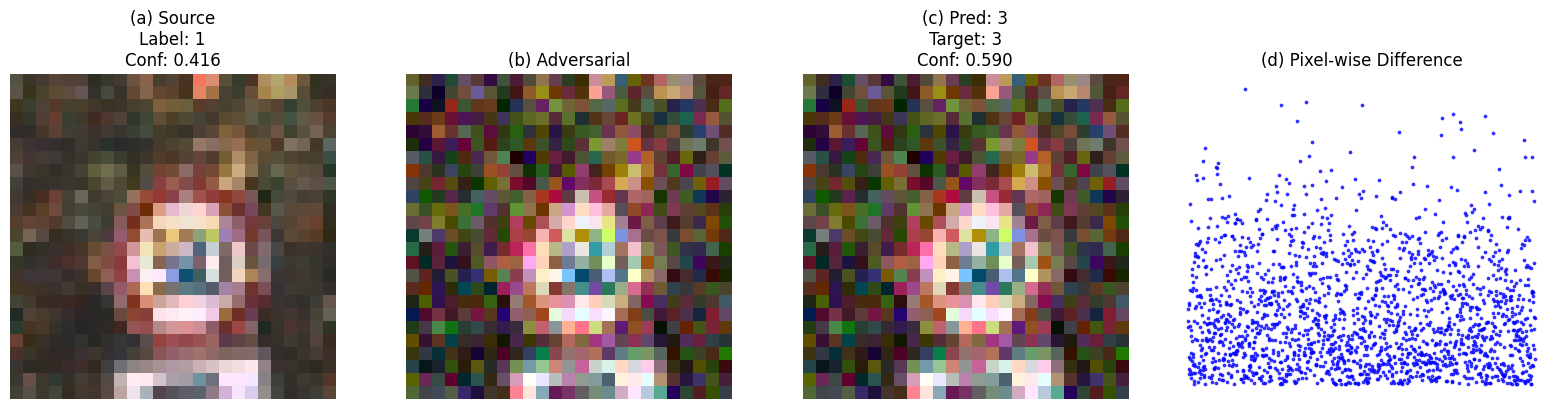

Image 5 (00002_00073_00022.png) | L2 Distance: 3.936341


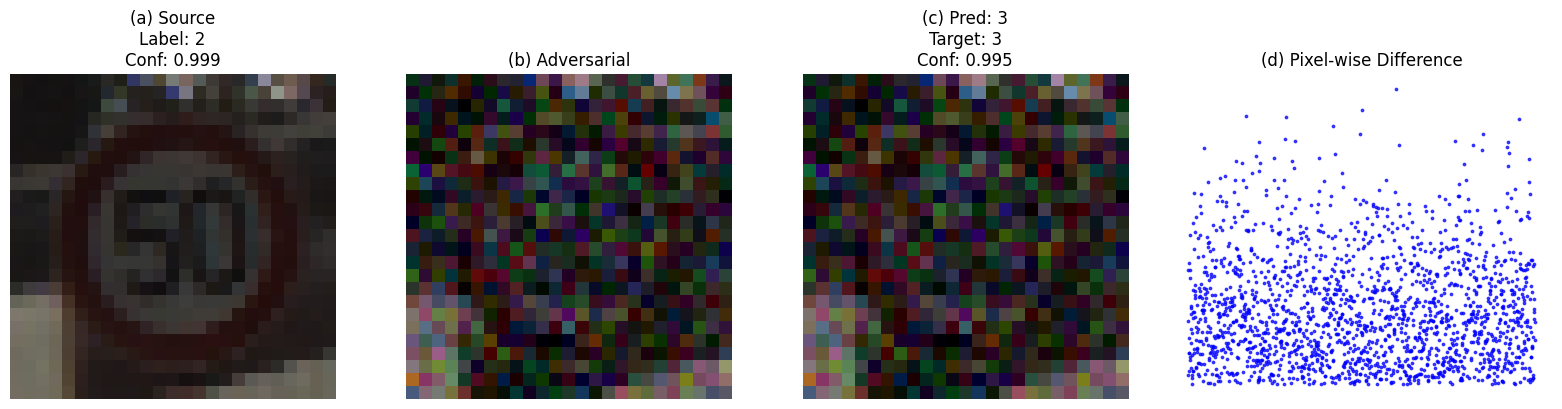


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 5
Success Rate: 100.00%
Mean L2: 4.1784
Std L2: 0.1863


In [ ]:
# ============================
# REPORTED IN PAPER: In Table Number 15, 17 and Supplementary information
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING (FIXED)
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['2']
TARGET_CLASS = class_indices['3']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('2')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 6
Target class index: 9
Image 1 (00014_00017_00011.png) | L2 Distance: 4.074612


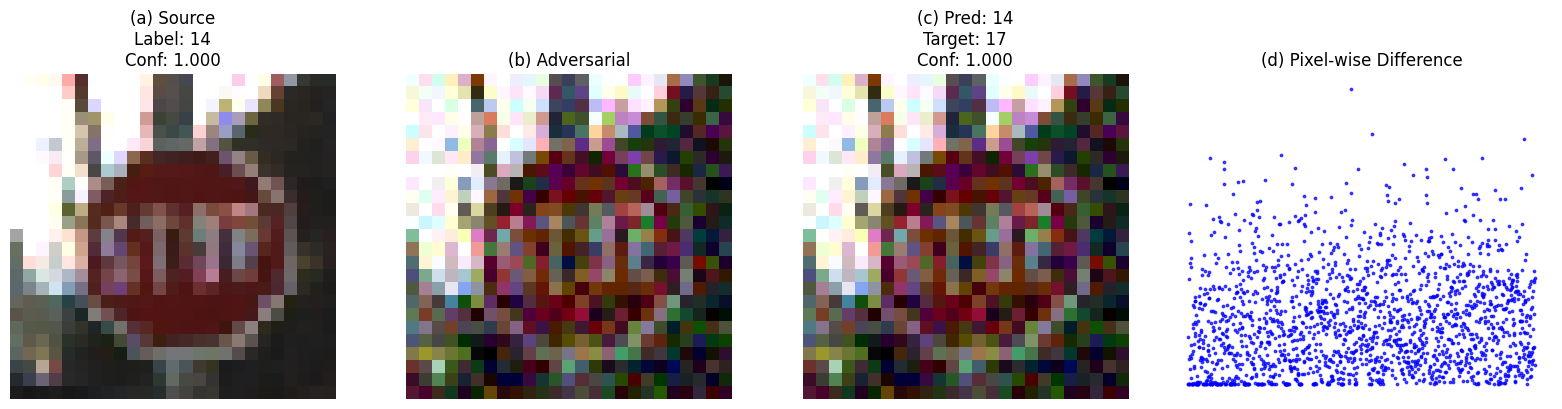

Image 2 (00014_00018_00029.png) | L2 Distance: 4.238073


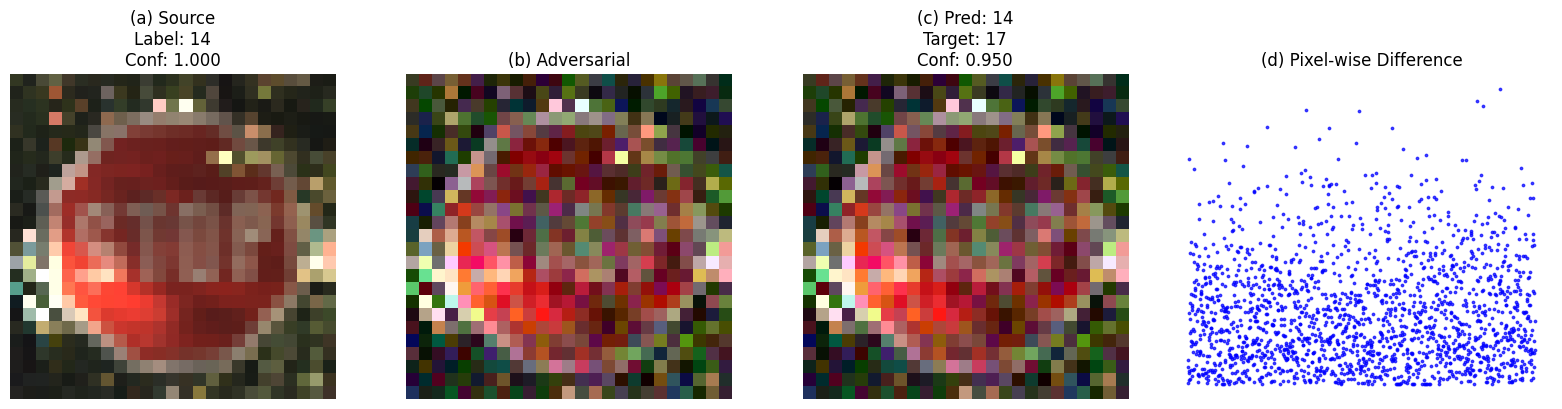

Image 3 (00014_00003_00029.png) | L2 Distance: 3.847016


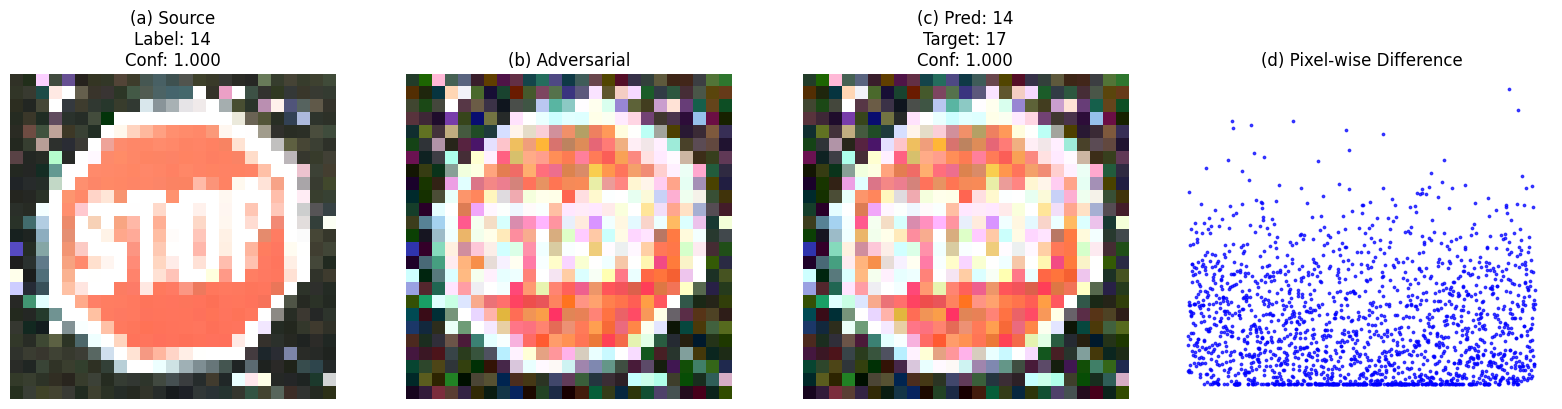

Image 4 (00014_00012_00019.png) | L2 Distance: 4.407586


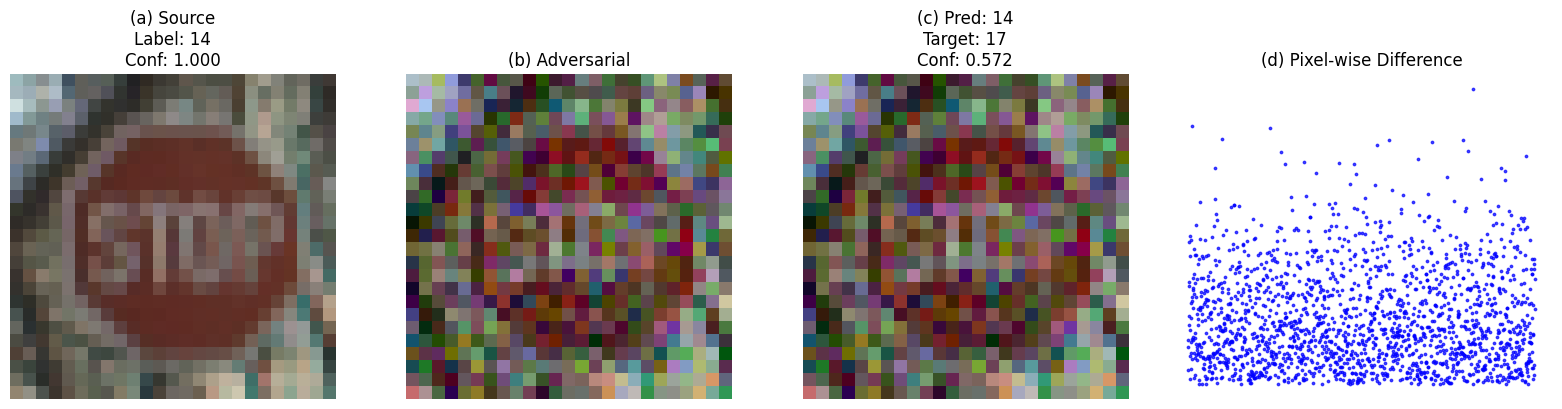

Image 5 (00014_00001_00020.png) | L2 Distance: 4.092677


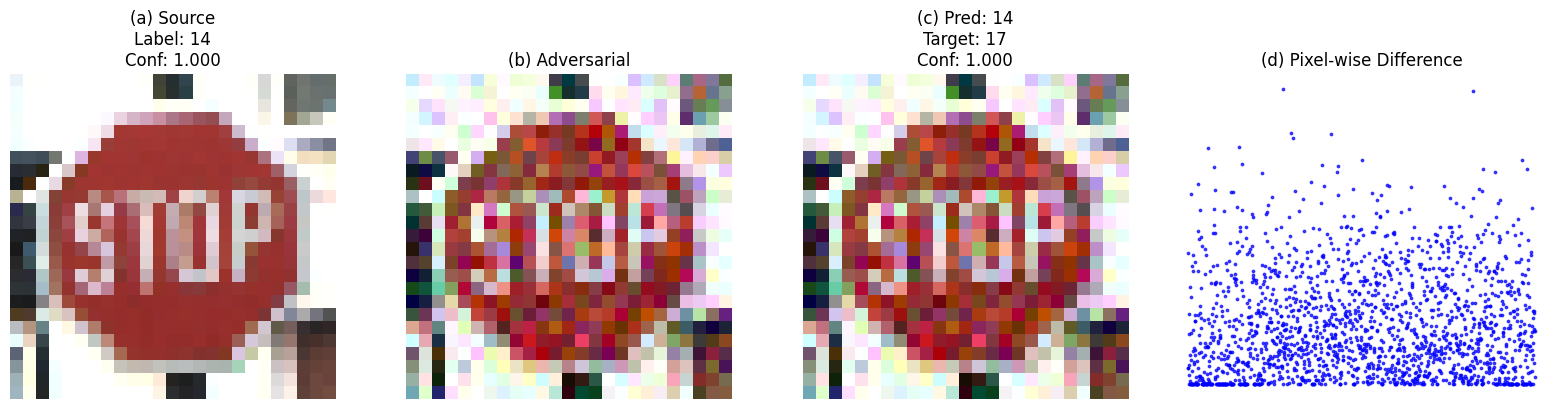


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 0
Success Rate: 0.00%
Mean L2: 4.1320
Std L2: 0.1861


In [ ]:
# ============================
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING (FIXED)
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['14']
TARGET_CLASS = class_indices['17']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('14')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 27
Target class index: 30
Image 1 (00033_00016_00028.png) | L2 Distance: 4.581076


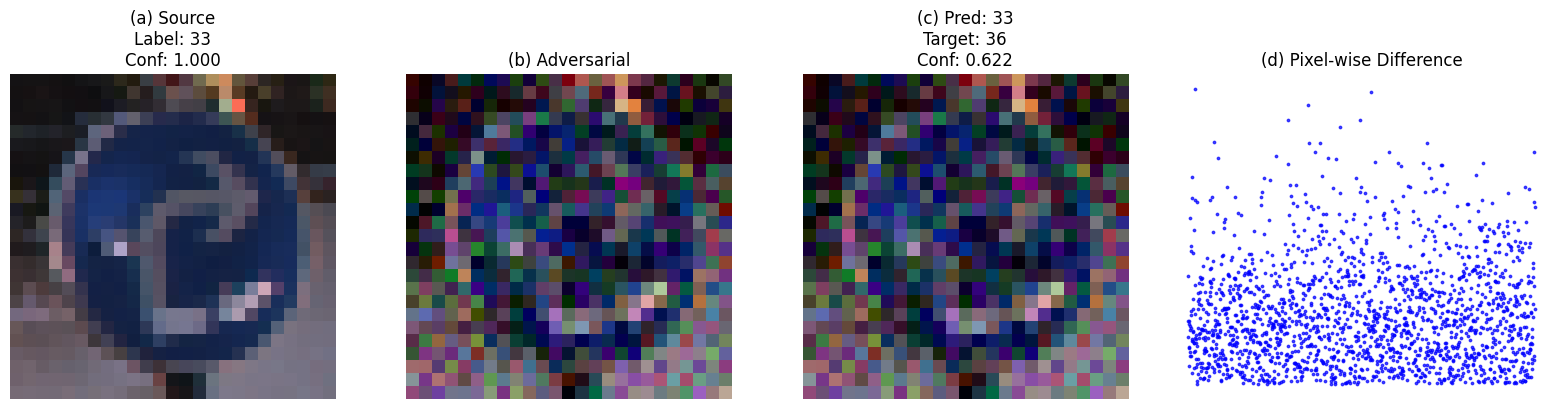

Image 2 (00033_00018_00002.png) | L2 Distance: 4.237494


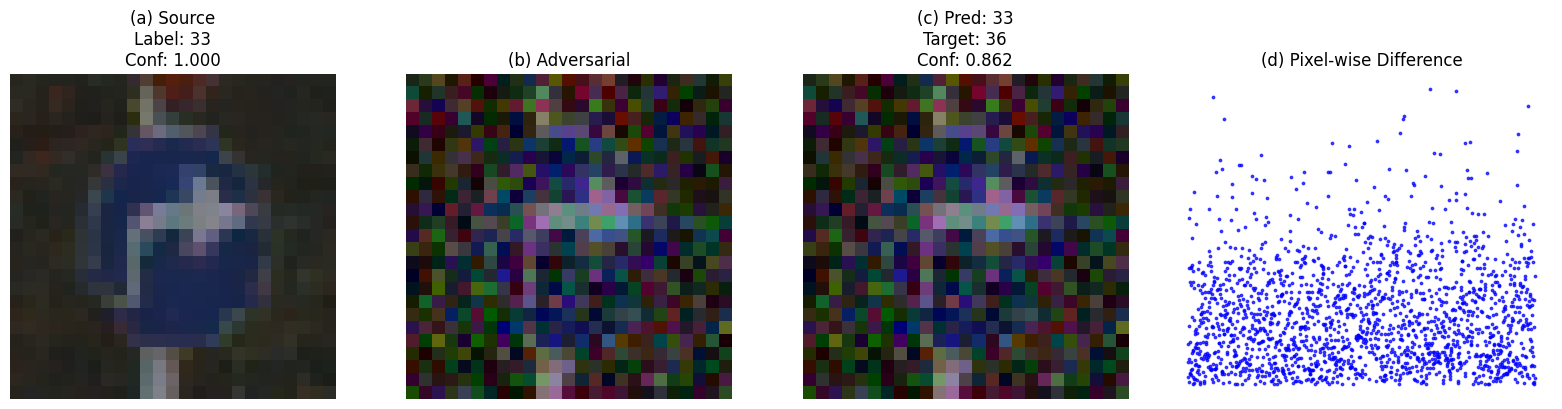

Image 3 (00033_00016_00021.png) | L2 Distance: 4.249896


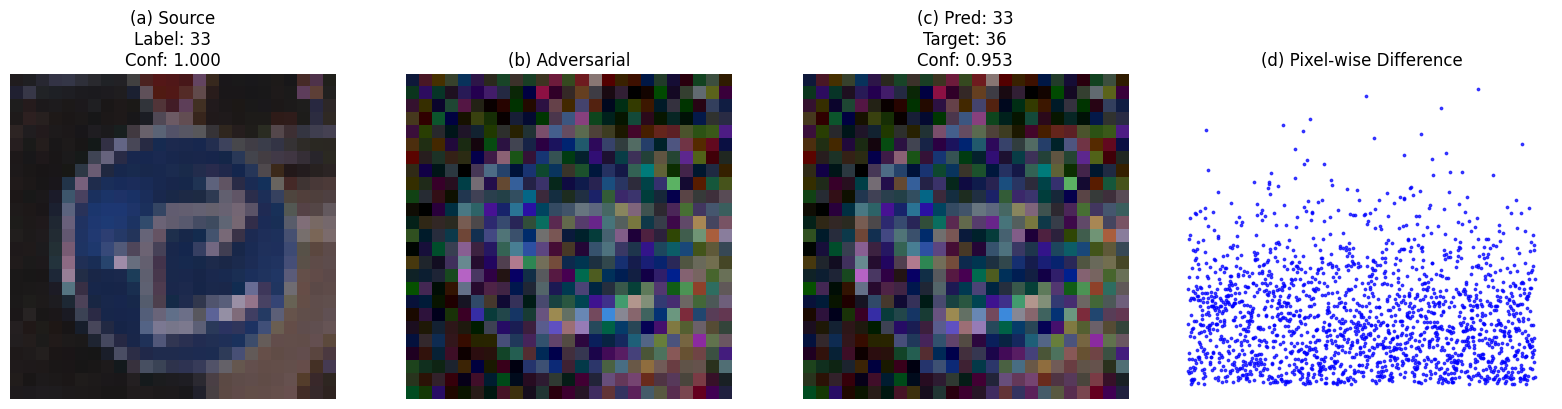

Image 4 (00033_00012_00000.png) | L2 Distance: 3.342549


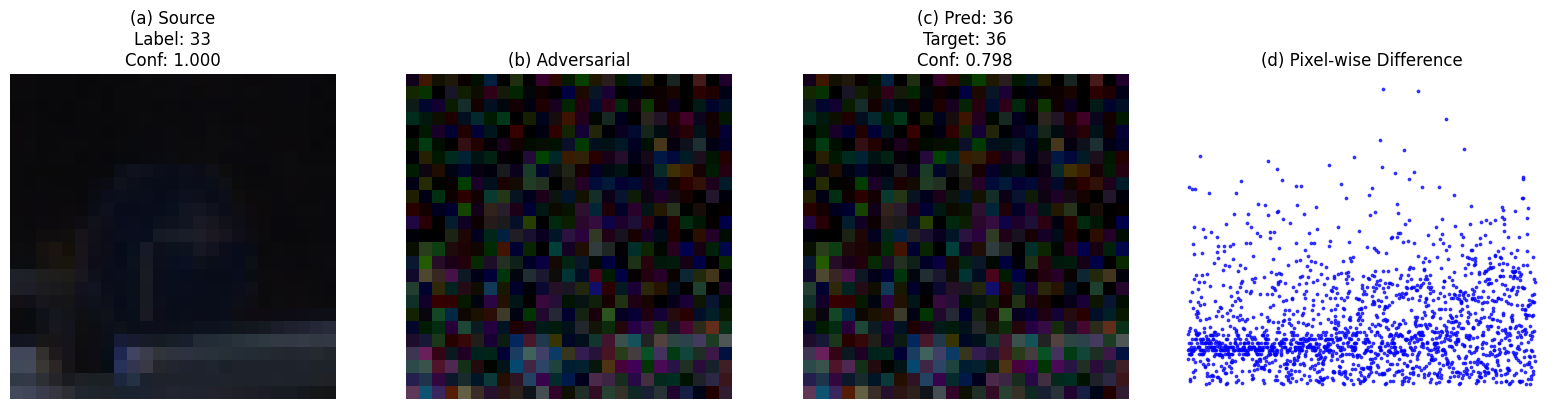

Image 5 (00033_00001_00011.png) | L2 Distance: 4.289200


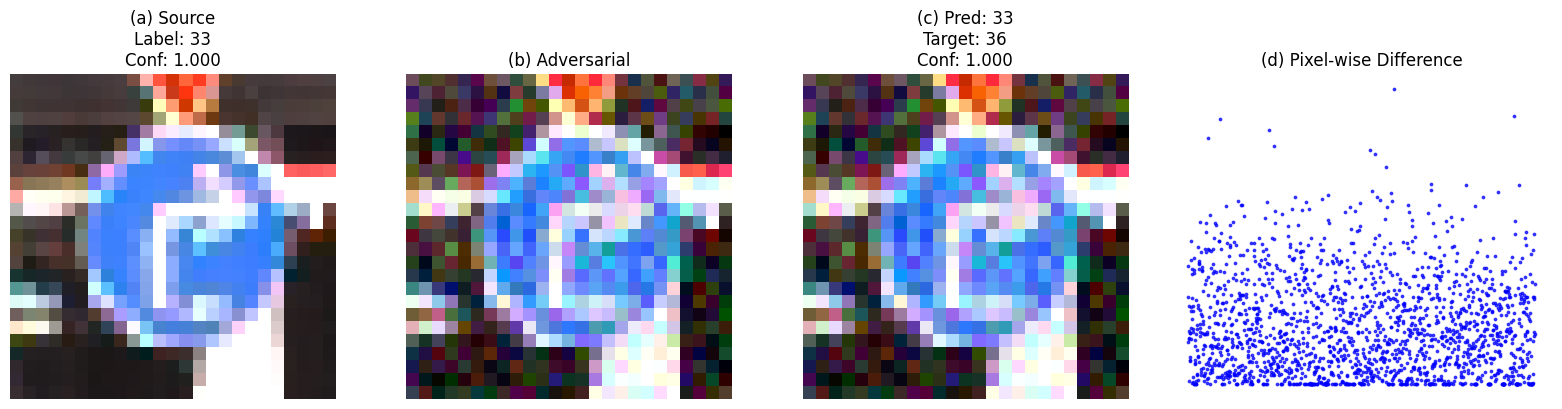


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 1
Success Rate: 20.00%
Mean L2: 4.1400
Std L2: 0.4182


In [ ]:
# ============================
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING (FIXED)
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['33']
TARGET_CLASS = class_indices['36']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('33')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 16
Target class index: 17
Image 1 (00023_00000_00027.png) | L2 Distance: 4.298573


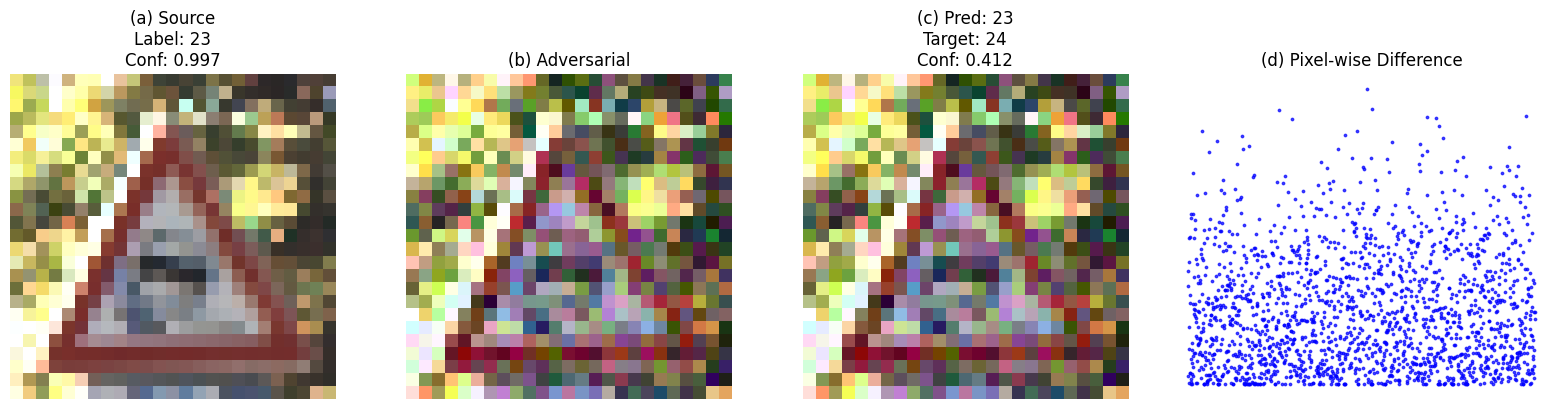

Image 2 (00023_00002_00013.png) | L2 Distance: 4.104972


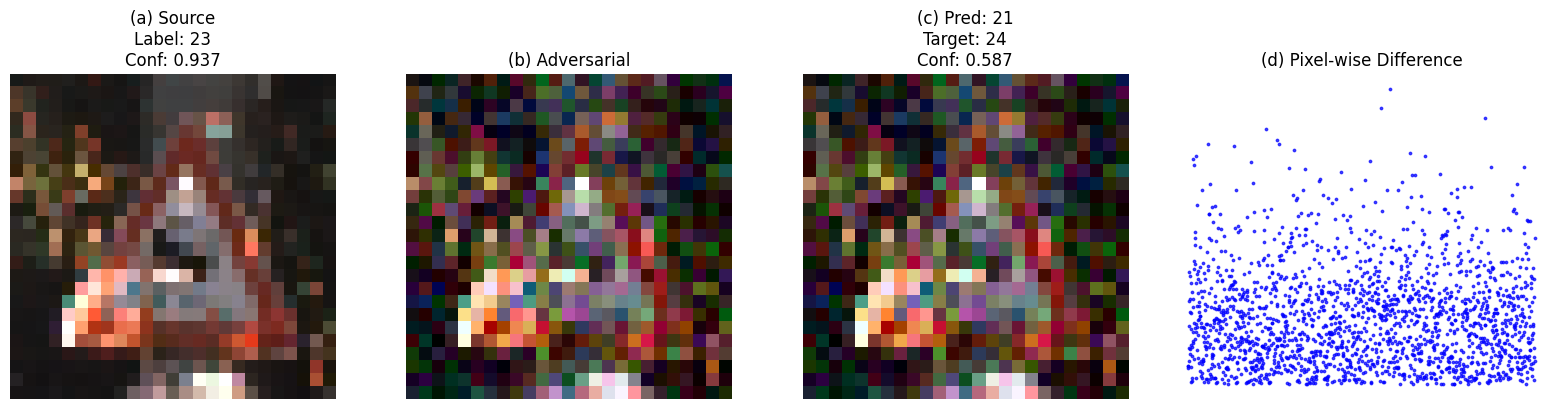

Image 3 (00023_00012_00000.png) | L2 Distance: 4.473421


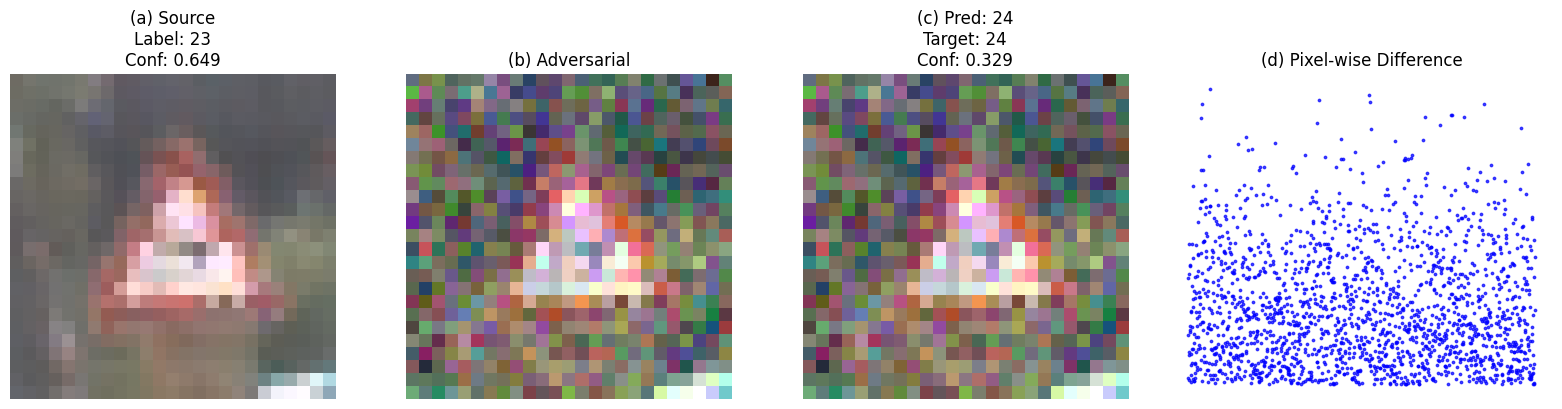

Image 4 (00023_00013_00022.png) | L2 Distance: 4.315566


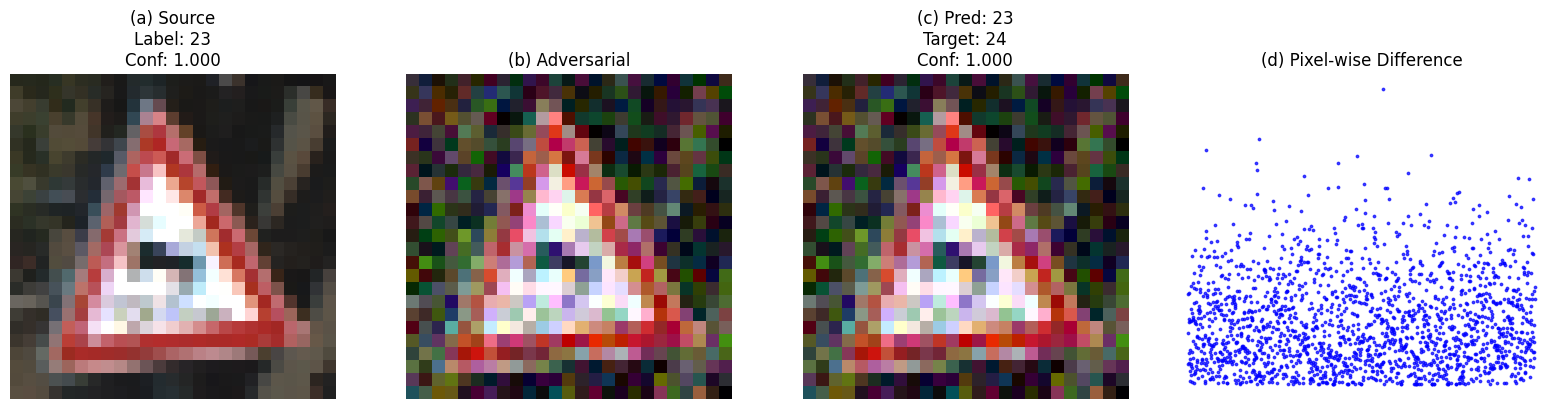

Image 5 (00023_00007_00021.png) | L2 Distance: 4.464229


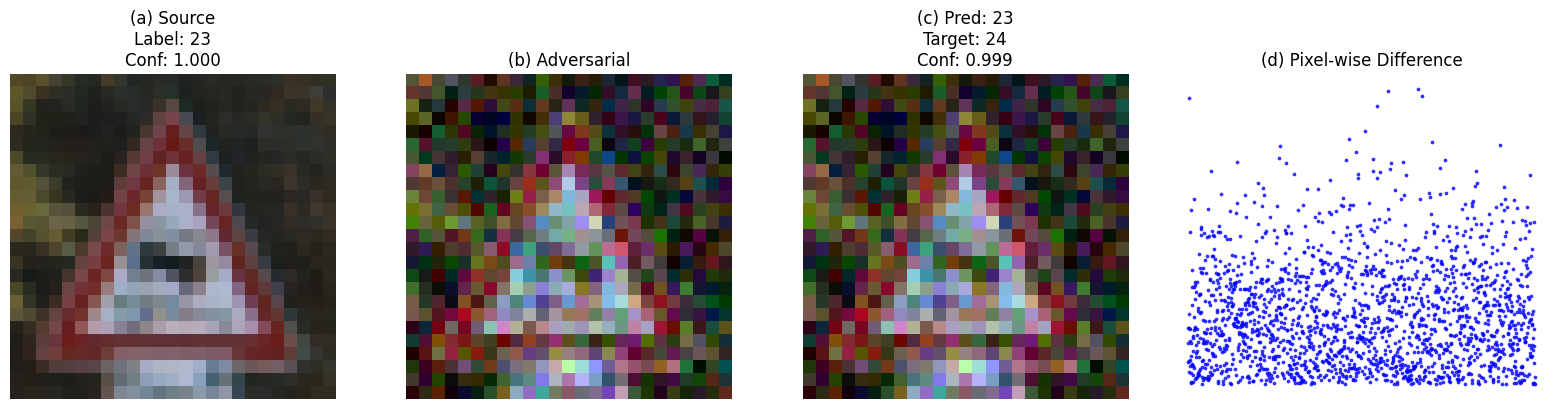


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 1
Success Rate: 20.00%
Mean L2: 4.3314
Std L2: 0.1345


In [ ]:
# ============================
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['23']
TARGET_CLASS = class_indices['24']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('23')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 3
Target class index: 24
Image 1 (00011_00029_00017.png) | L2 Distance: 4.427598


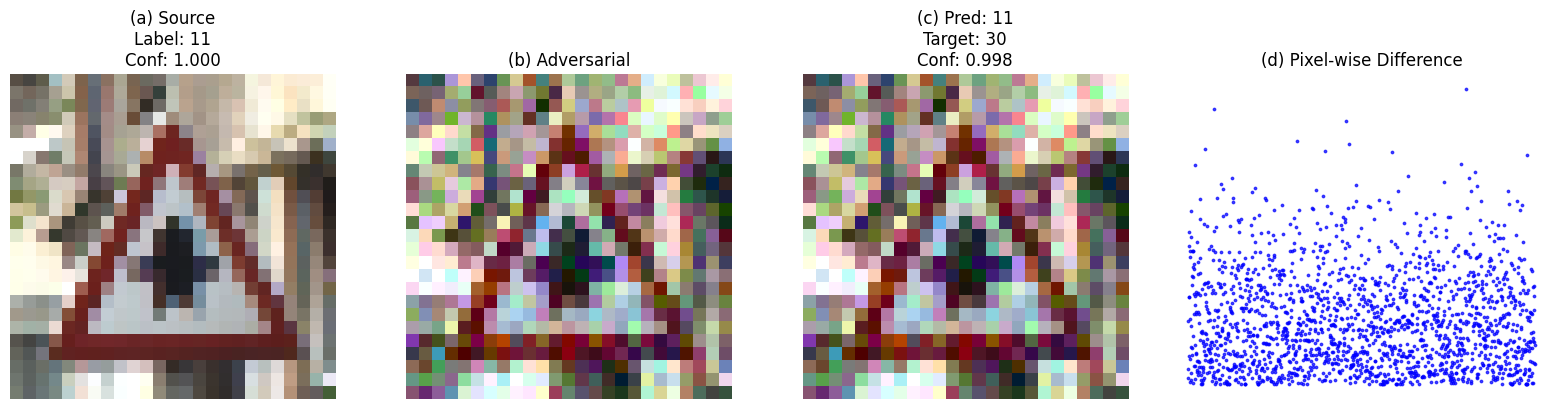

Image 2 (00011_00015_00007.png) | L2 Distance: 4.243426


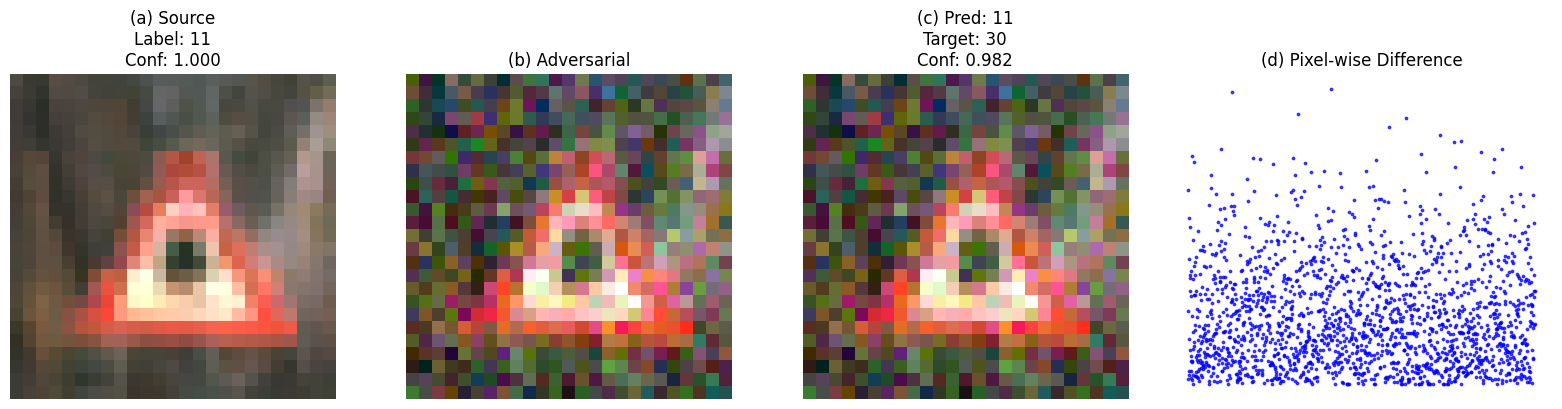

Image 3 (00011_00012_00016.png) | L2 Distance: 4.129682


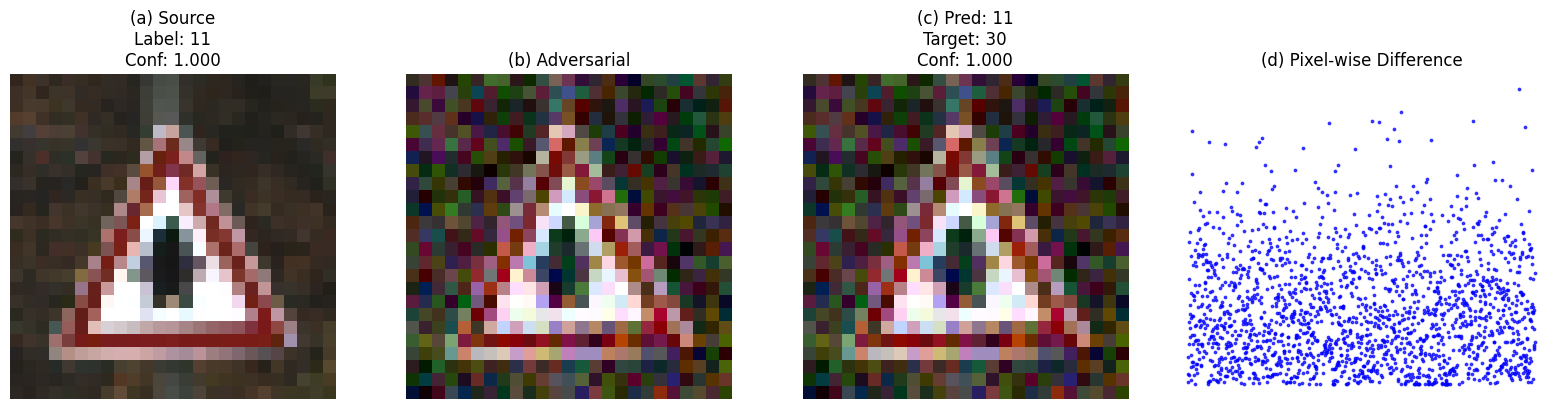

Image 4 (00011_00039_00014.png) | L2 Distance: 4.218648


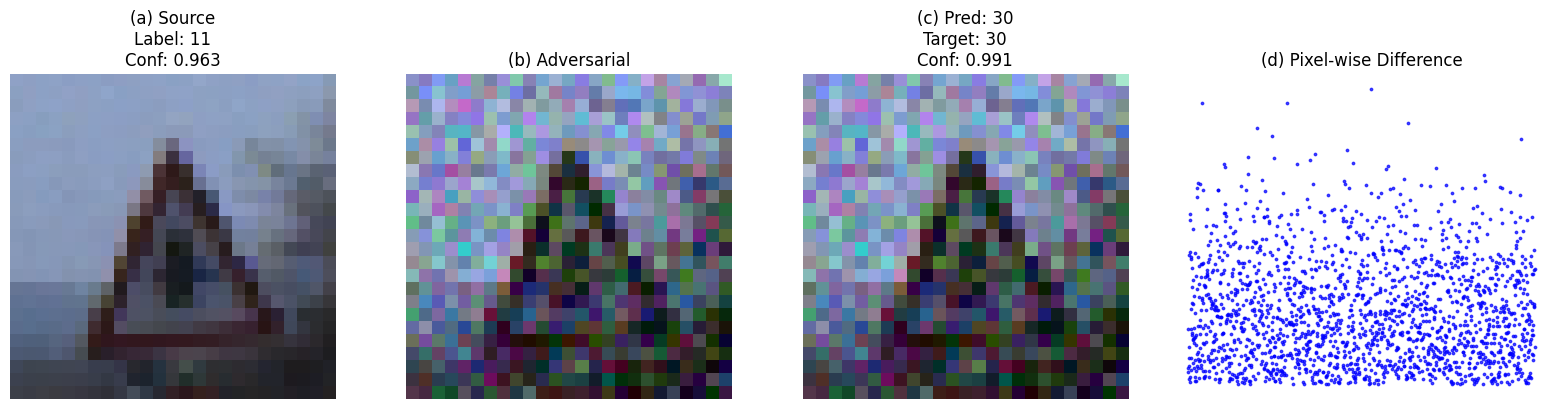

Image 5 (00011_00007_00006.png) | L2 Distance: 4.434128


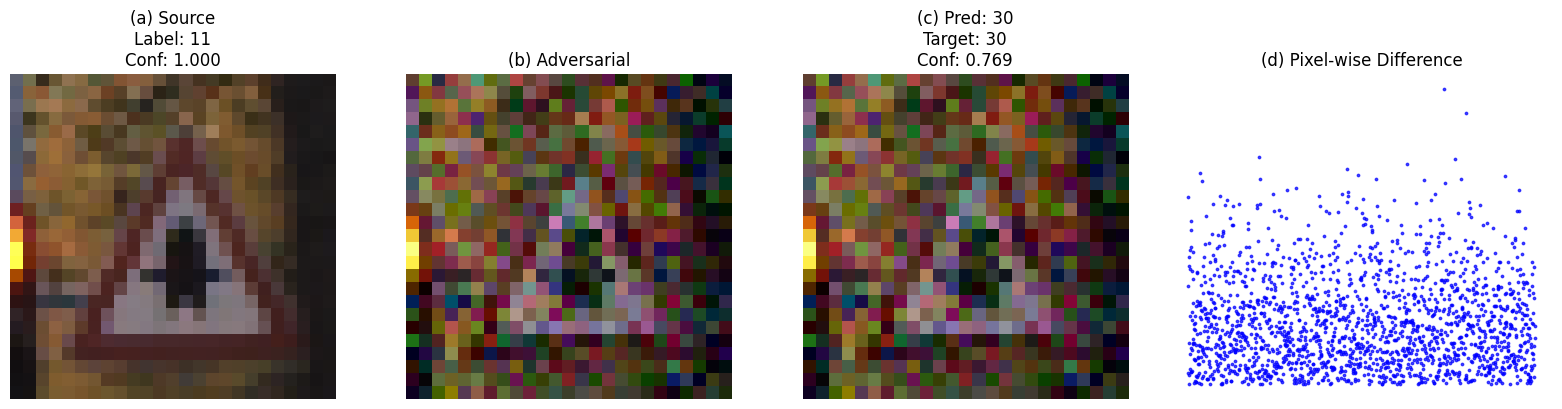


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 2
Success Rate: 40.00%
Mean L2: 4.2907
Std L2: 0.1206


In [ ]:
# ============================
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING (FIXED)
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['11']
TARGET_CLASS = class_indices['30']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('11')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 31
Target class index: 35
Image 1 (00037_00000_00014.png) | L2 Distance: 4.008659


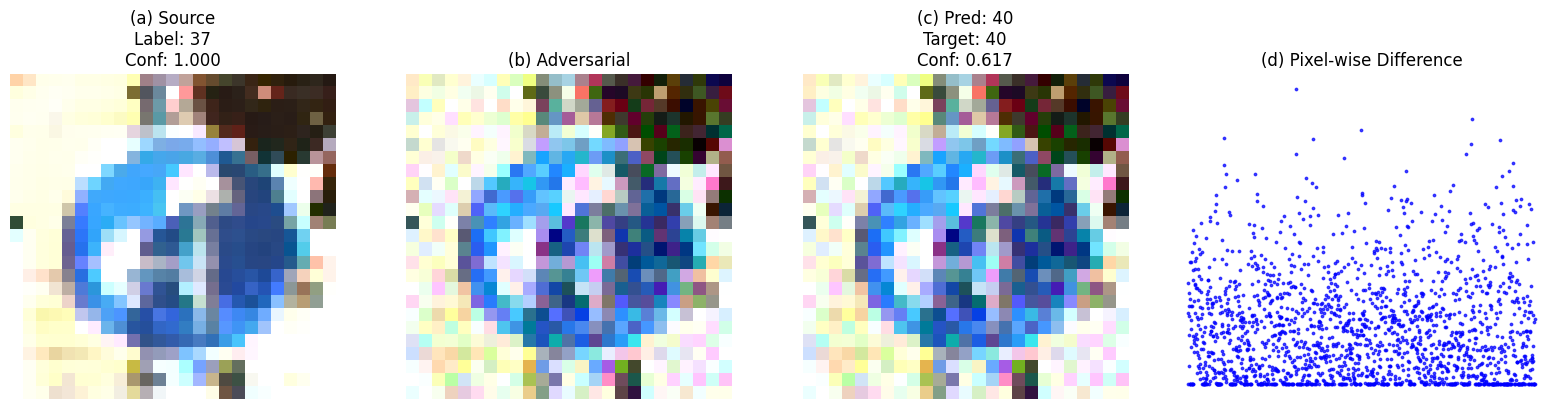

Image 2 (00037_00003_00021.png) | L2 Distance: 4.332901


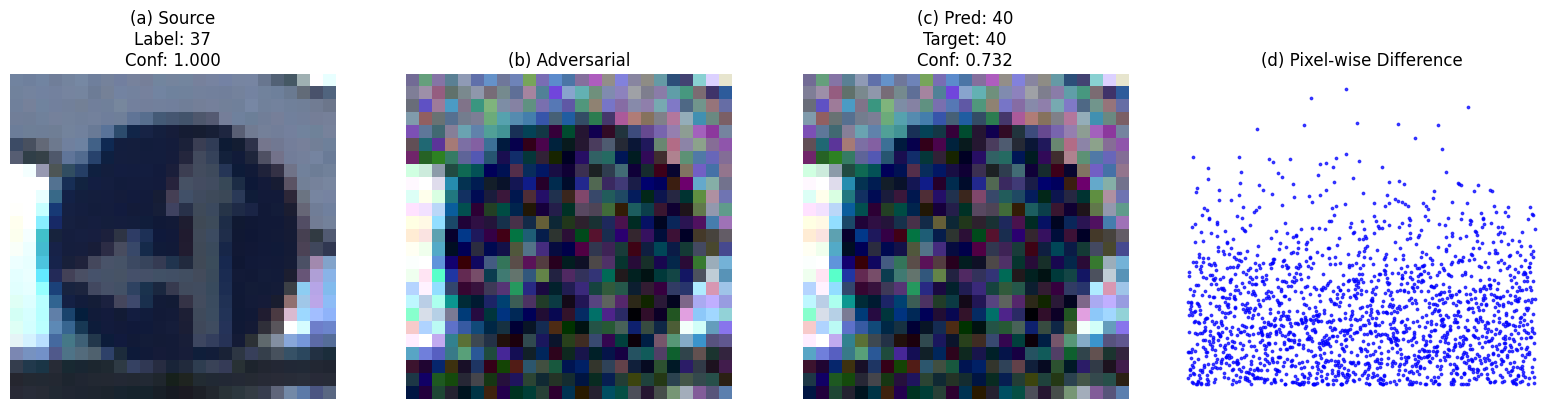

Image 3 (00037_00006_00007.png) | L2 Distance: 4.770112


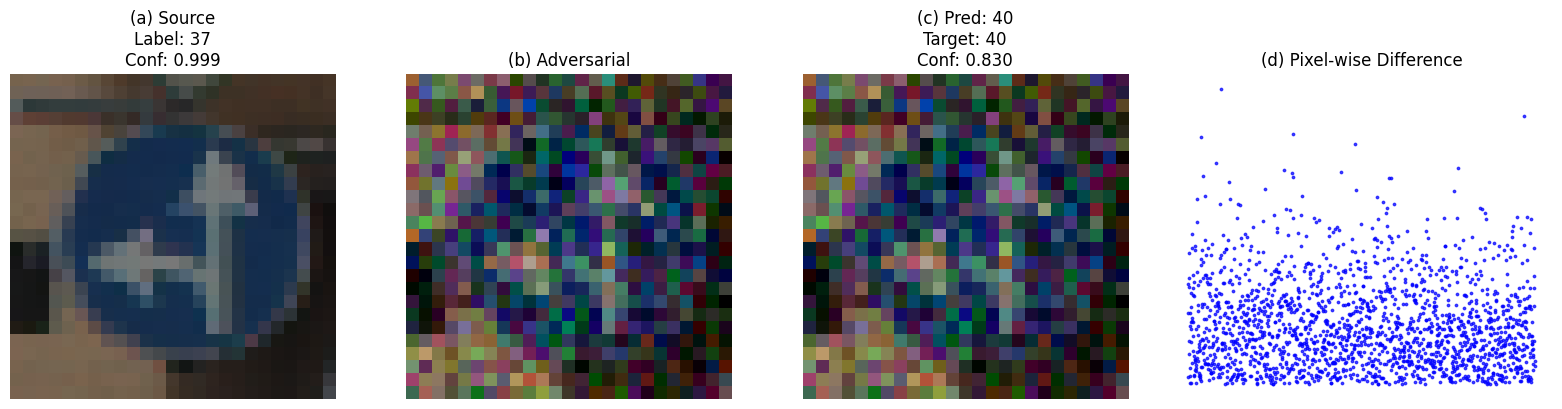

Image 4 (00037_00005_00003.png) | L2 Distance: 4.266063


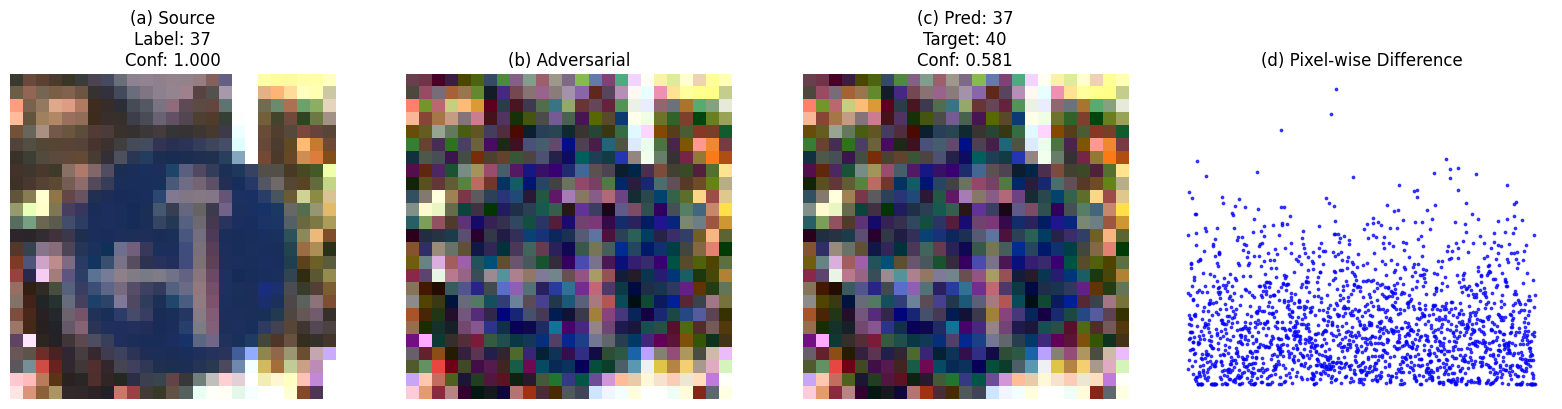

Image 5 (00037_00004_00002.png) | L2 Distance: 4.516257


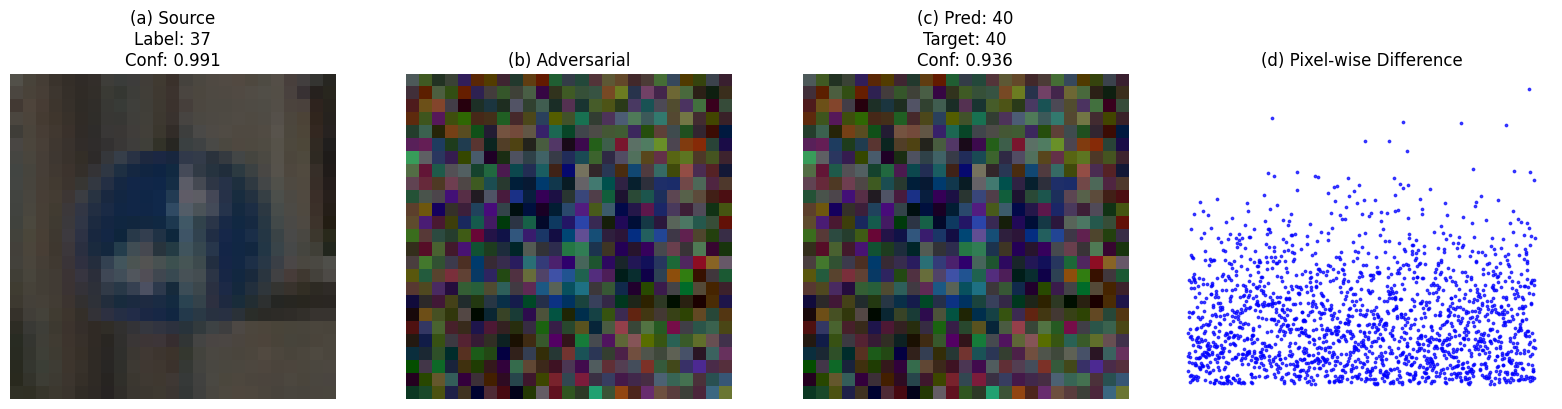


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 4
Success Rate: 80.00%
Mean L2: 4.3788
Std L2: 0.2545


In [ ]:
# ============================
# REPORTED IN PAPER: In Table Number 15, 17 and Supplementary information
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING (FIXED)
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['37']
TARGET_CLASS = class_indices['40']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('37')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 9
Target class index: 6
Image 1 (00017_00007_00008.png) | L2 Distance: 4.128406


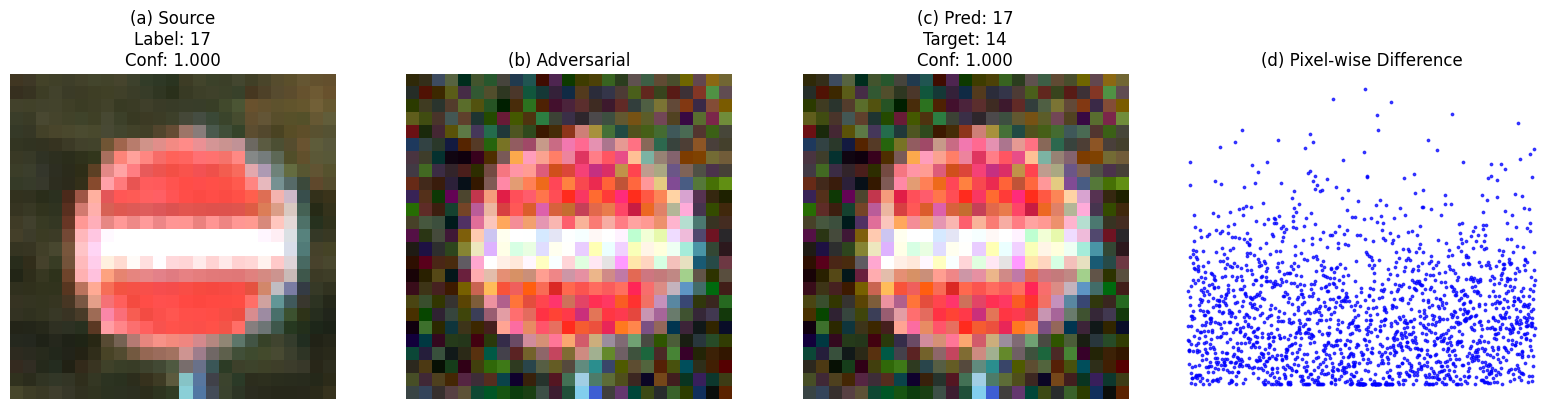

Image 2 (00017_00015_00012.png) | L2 Distance: 4.538686


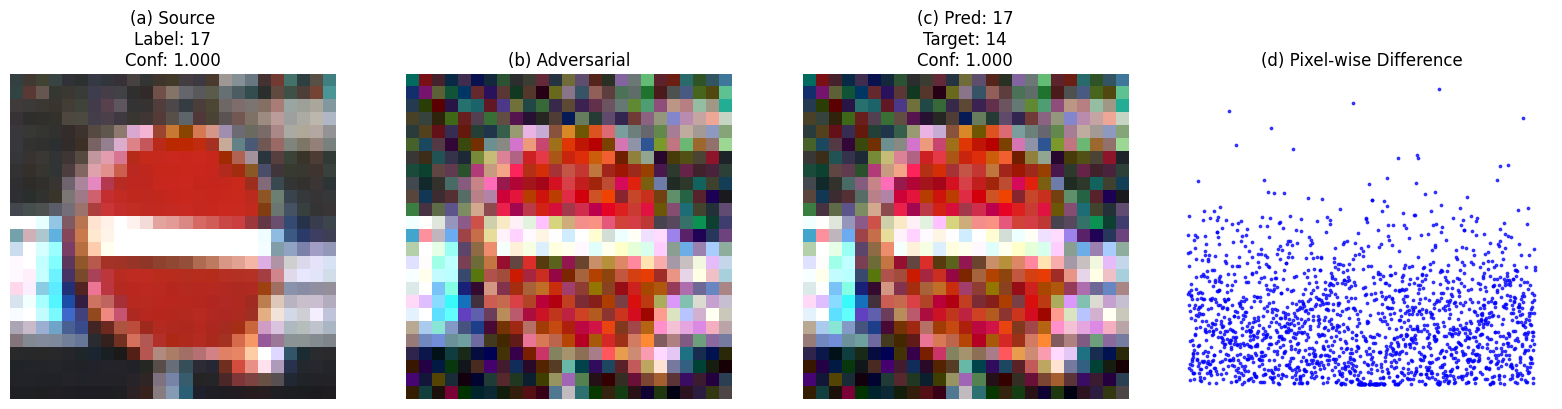

Image 3 (00017_00017_00007.png) | L2 Distance: 4.672288


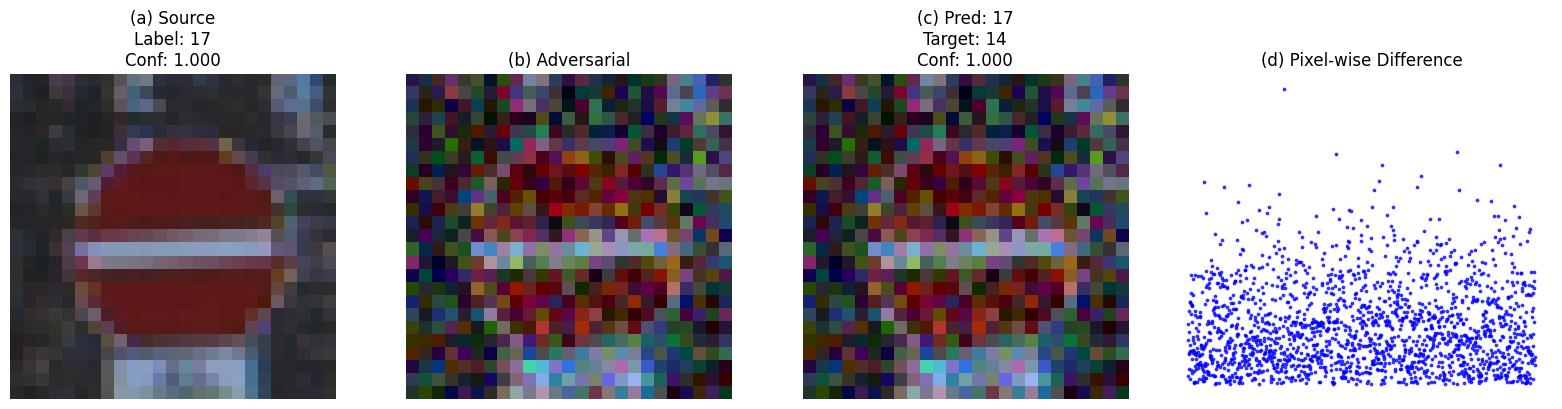

Image 4 (00017_00023_00026.png) | L2 Distance: 4.232389


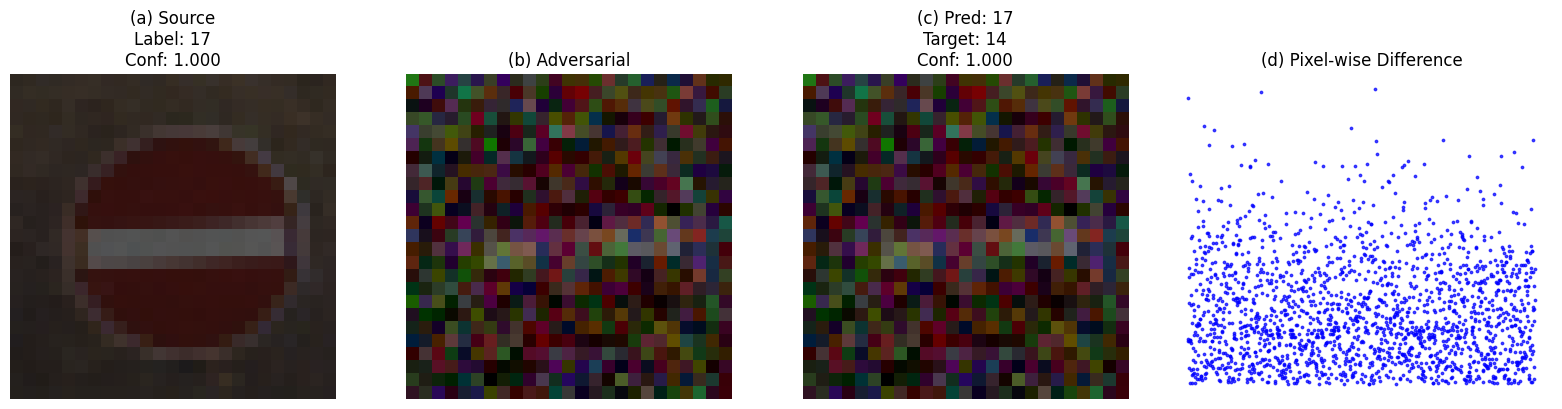

Image 5 (00017_00022_00009.png) | L2 Distance: 3.254847


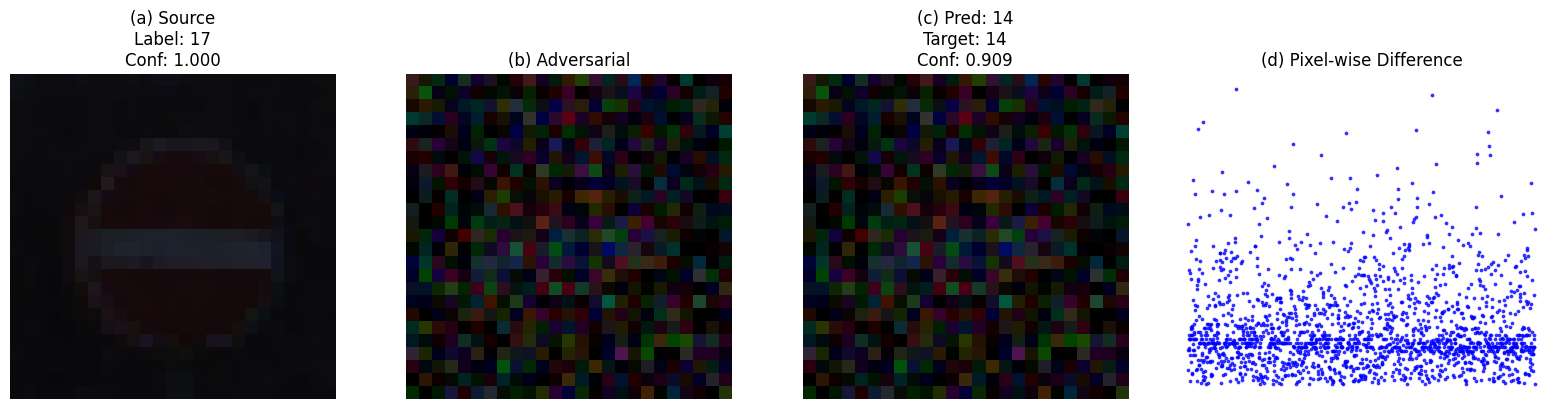


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 1
Success Rate: 20.00%
Mean L2: 4.1653
Std L2: 0.4962


In [ ]:
# ============================
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING (FIXED)
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['17']
TARGET_CLASS = class_indices['14']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('17')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 6
Target class index: 7
Image 1 (00014_00016_00004.png) | L2 Distance: 4.397351


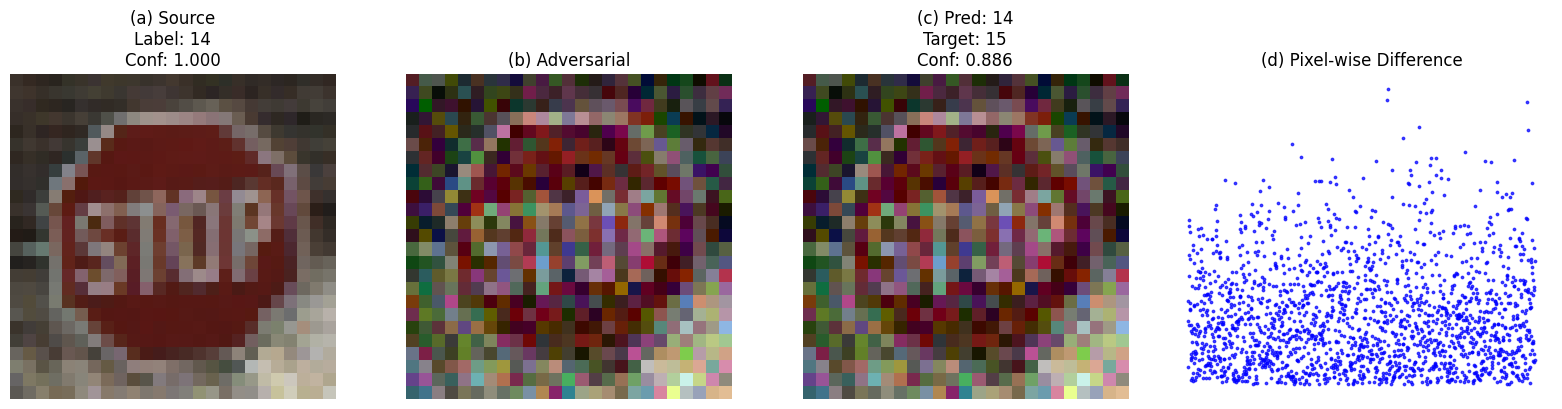

Image 2 (00014_00020_00016.png) | L2 Distance: 4.237834


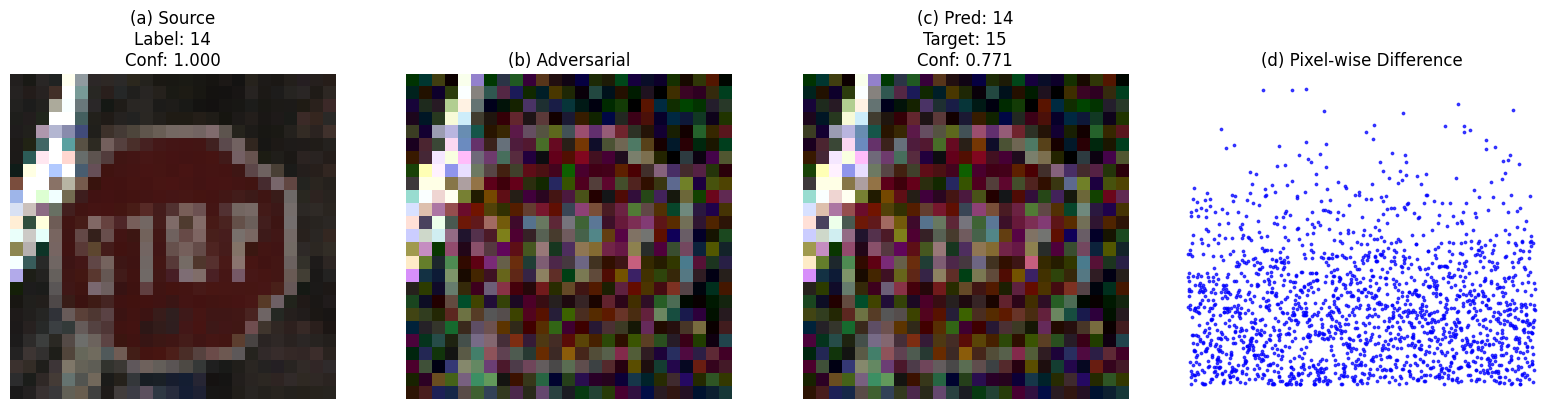

Image 3 (00014_00020_00023.png) | L2 Distance: 3.989513


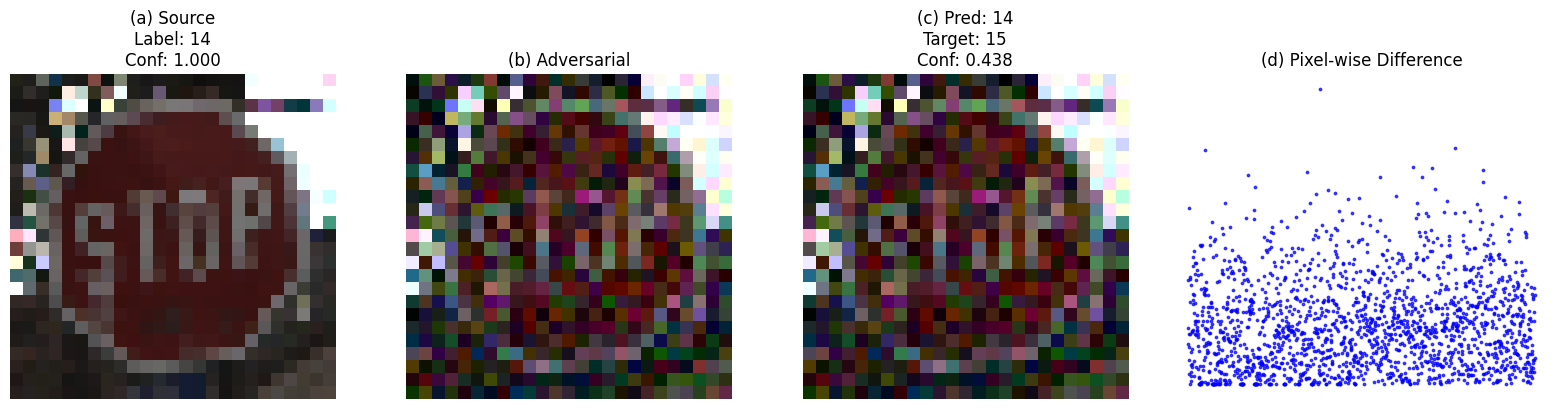

Image 4 (00014_00011_00026.png) | L2 Distance: 3.576650


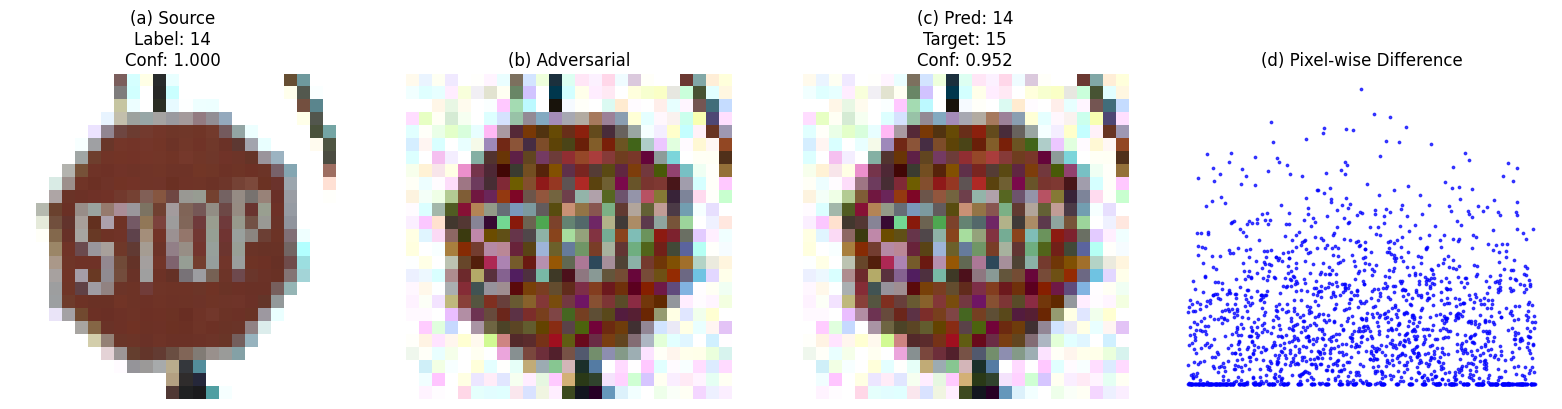

Image 5 (00014_00020_00003.png) | L2 Distance: 4.299481


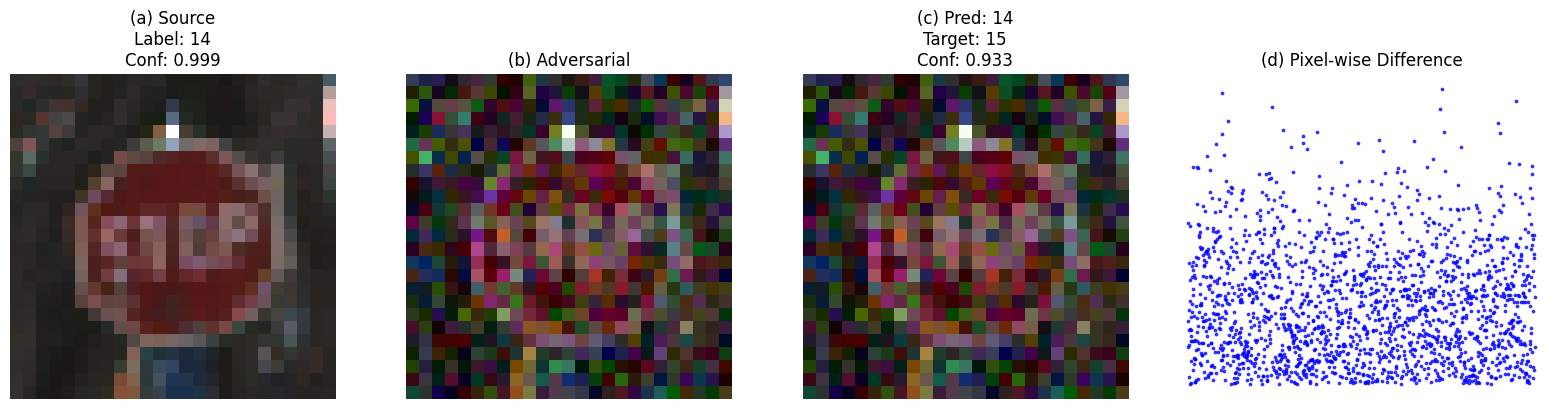


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 0
Success Rate: 0.00%
Mean L2: 4.1002
Std L2: 0.2944


In [ ]:
# ============================
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING (FIXED)
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['14']
TARGET_CLASS = class_indices['15']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('14')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 9
Target class index: 6
Image 1 (00017_00026_00023.png) | L2 Distance: 4.257820


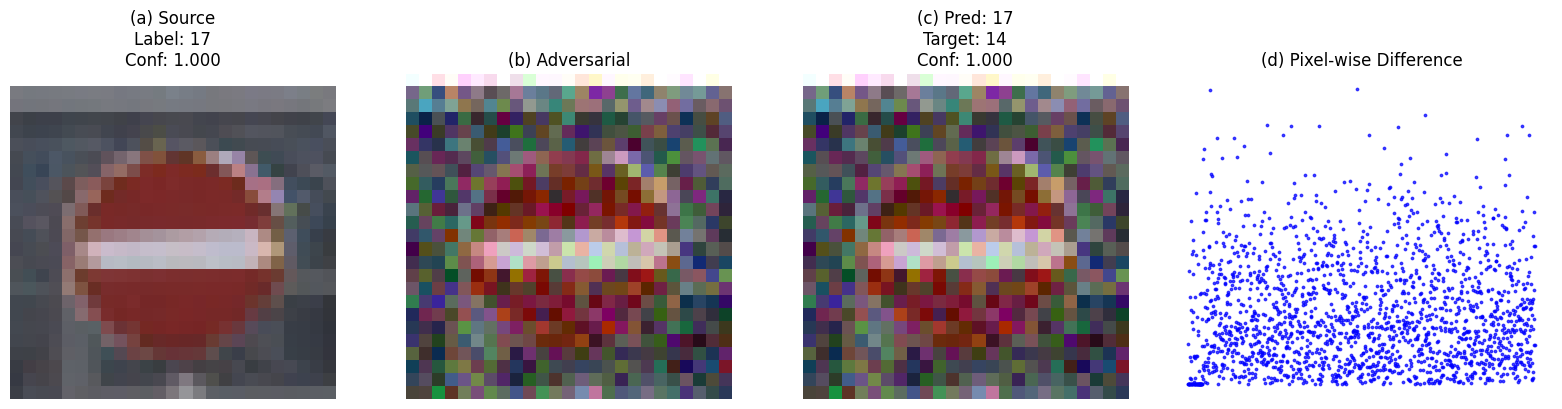

Image 2 (00017_00019_00028.png) | L2 Distance: 3.599738


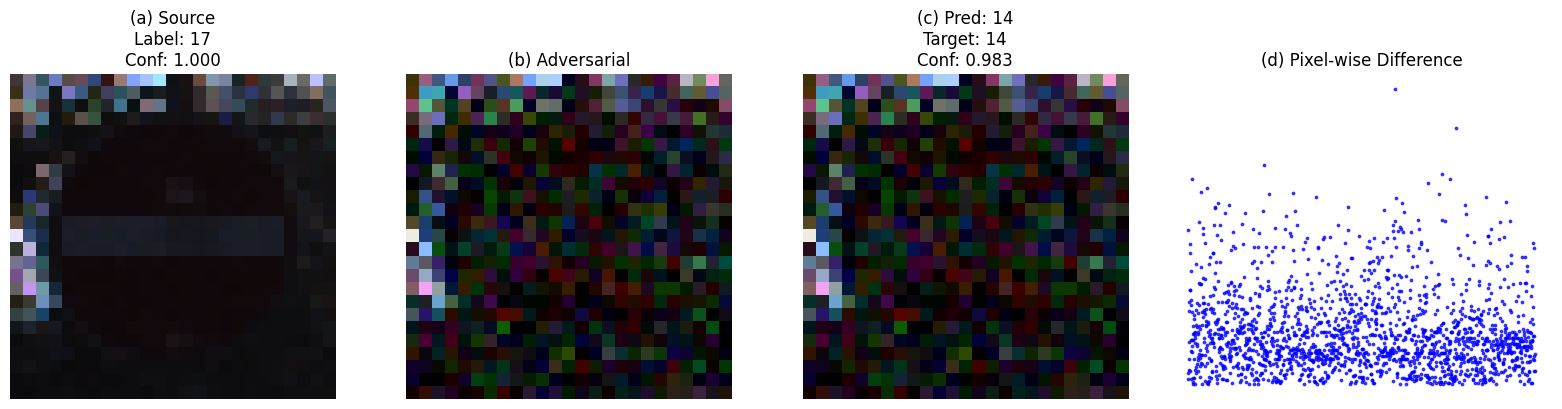

Image 3 (00017_00022_00008.png) | L2 Distance: 3.451441


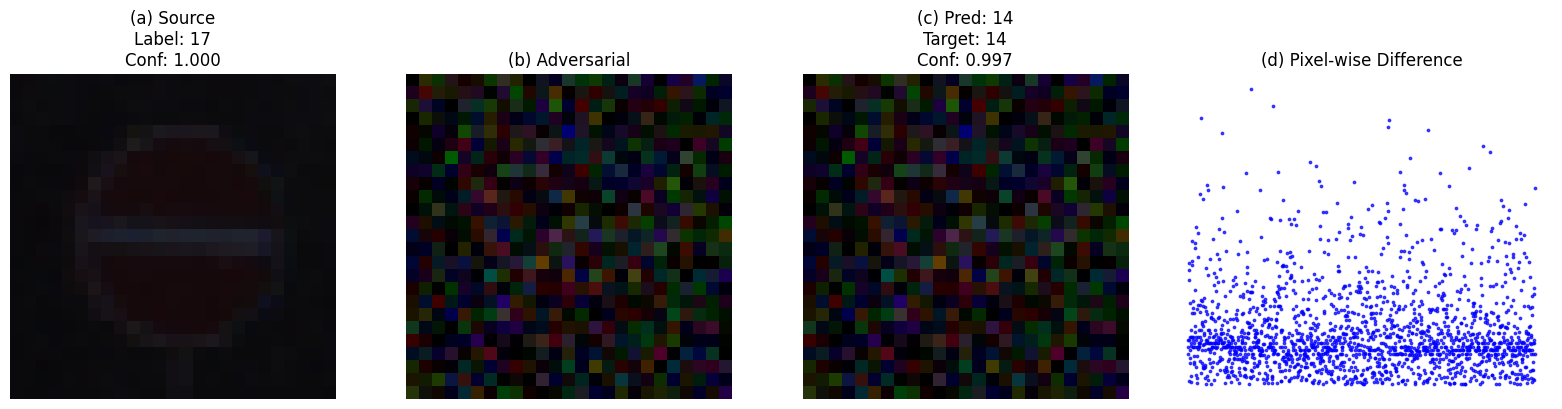

Image 4 (00017_00005_00013.png) | L2 Distance: 3.854415


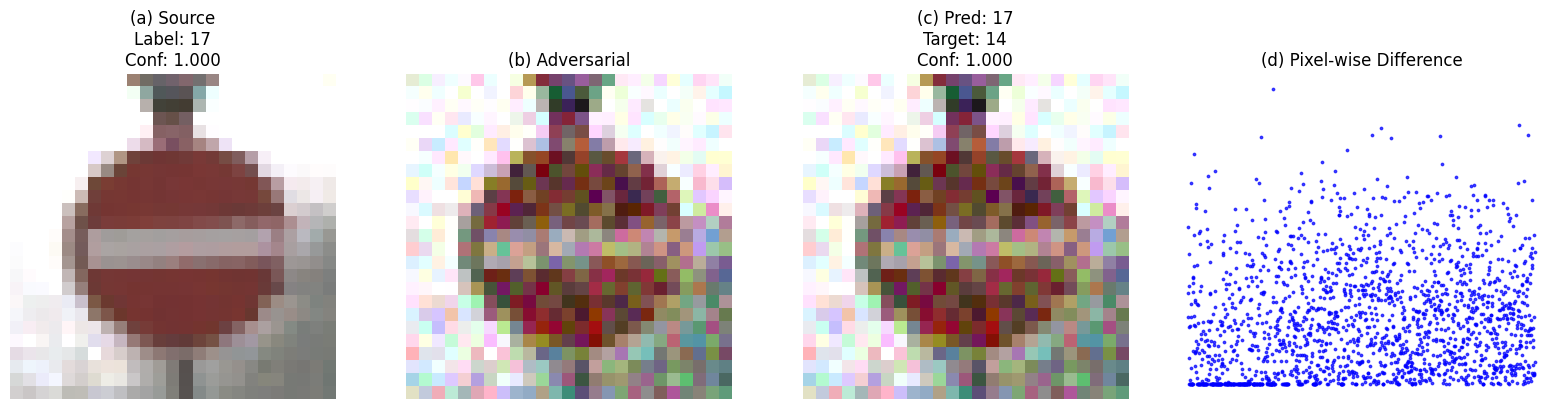

Image 5 (00017_00031_00015.png) | L2 Distance: 4.538800


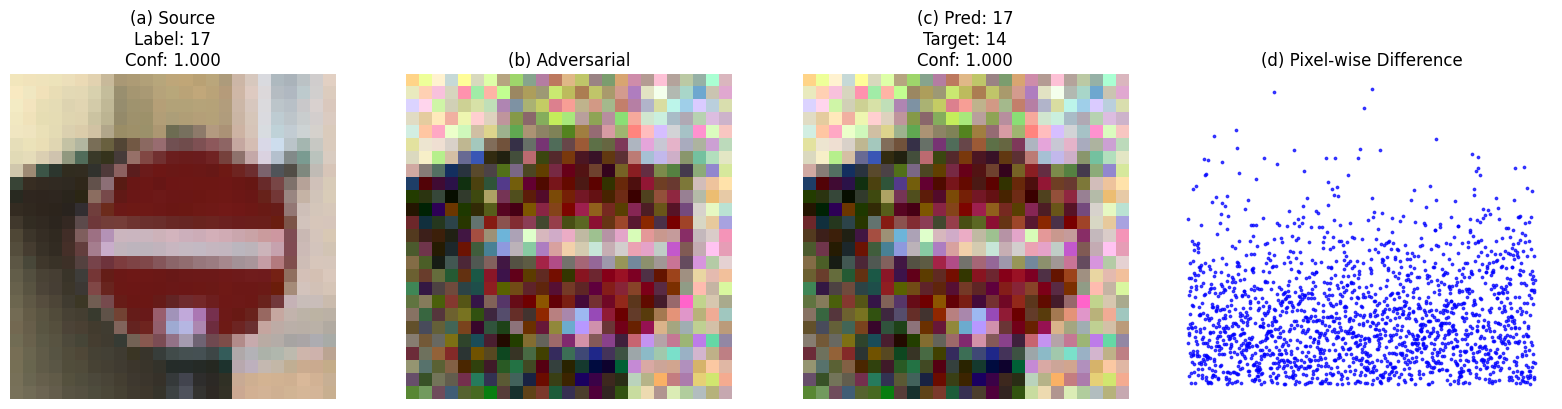


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 2
Success Rate: 40.00%
Mean L2: 3.9404
Std L2: 0.4053


In [ ]:
# ============================
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING (FIXED)
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['17']
TARGET_CLASS = class_indices['14']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('17')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")

Source class index: 15
Target class index: 18
Image 1 (00022_00000_00026.png) | L2 Distance: 4.608916


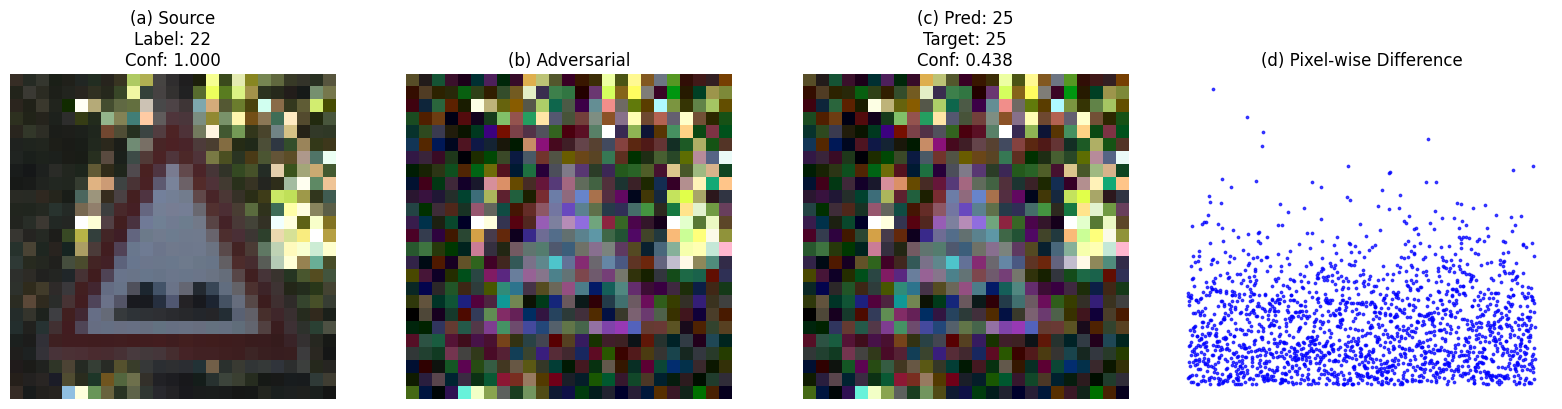

Image 2 (00022_00008_00022.png) | L2 Distance: 3.741725


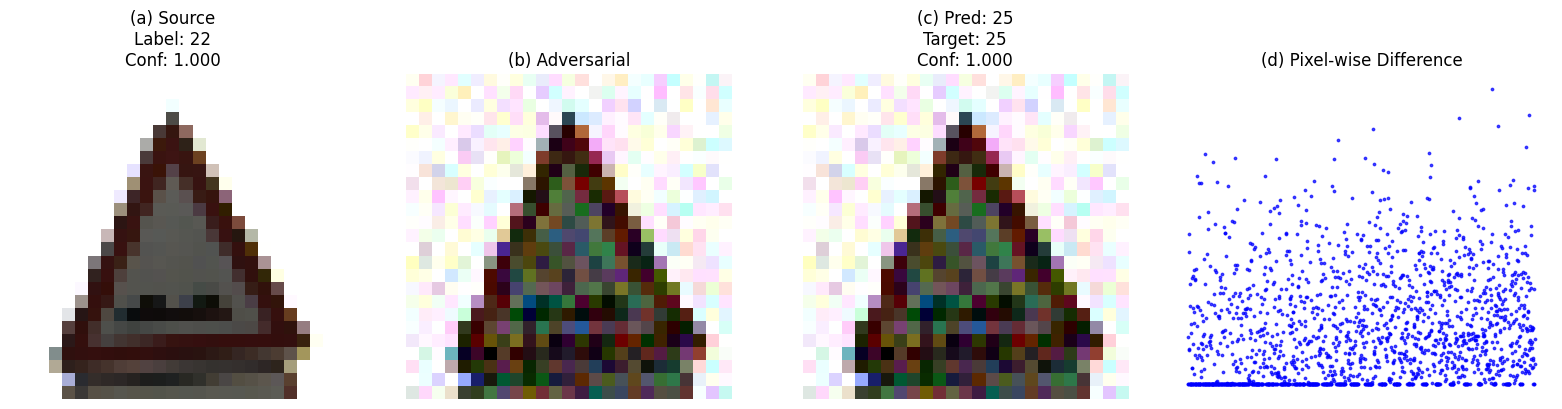

Image 3 (00022_00010_00014.png) | L2 Distance: 4.277423


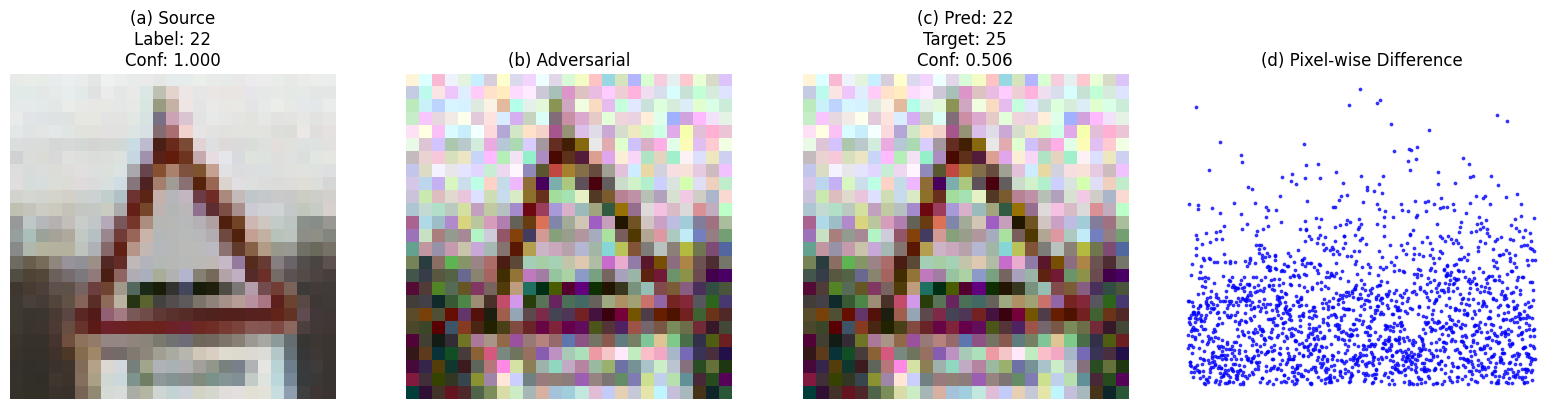

Image 4 (00022_00002_00012.png) | L2 Distance: 4.172210


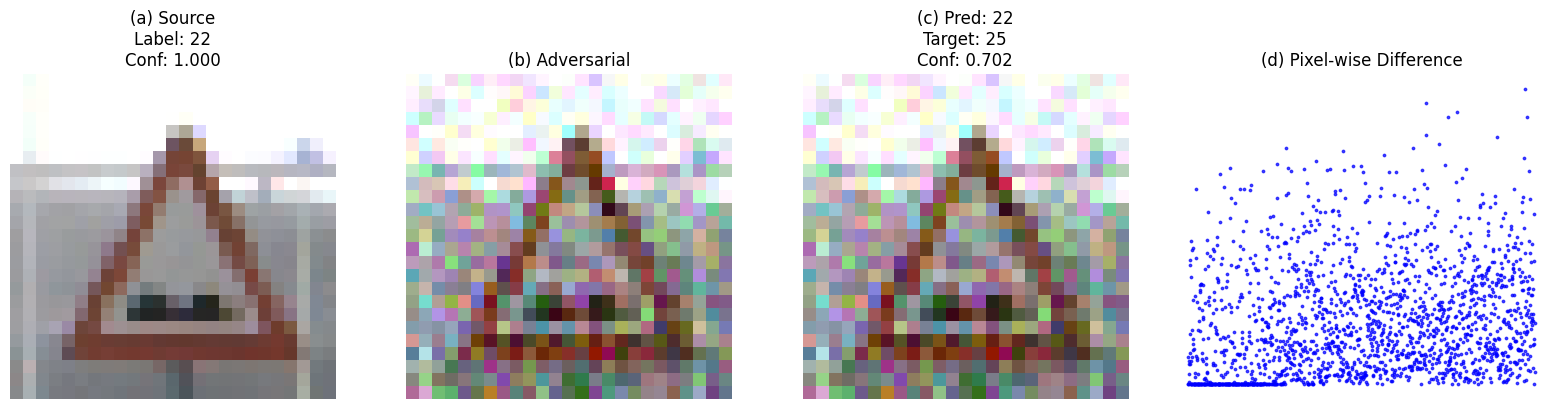

Image 5 (00022_00001_00023.png) | L2 Distance: 4.307468


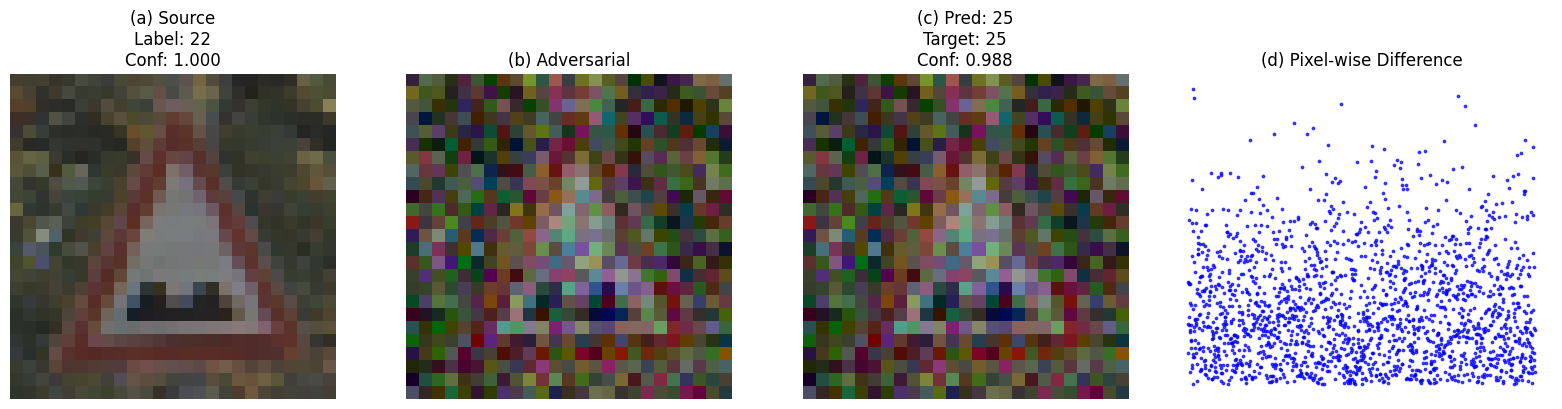


===== FINAL RESULTS =====
Total Images: 5
Successful Attacks: 3
Success Rate: 60.00%
Mean L2: 4.2215
Std L2: 0.2804


In [ ]:
# ============================
# REPORTED IN PAPER: In Table Number 15, 17 and Supplementary information
# STEP 7: MULTI-IMAGE EVALUATION
# ============================

import matplotlib.pyplot as plt

# ----------------------------
# Helper functions
# ----------------------------
def get_class_images(class_id):
    folder = os.path.join(DATA_DIR, str(class_id))
    imgs = glob(folder + "/*.png")
    return random.sample(imgs, min(SAMPLES_PER_CLASS, len(imgs)))

def preprocess(path):
    img = load_img(path, target_size=IMAGE_SIZE)
    return img_to_array(img) / 255.0

def plot_scatter(ax, src, adv):
    diff = np.abs(src - adv).reshape(-1)
    x = np.arange(len(diff))
    ax.scatter(x, diff, s=3, color='blue', alpha=0.7)
    ax.set_title("(d) Pixel-wise Difference")
    ax.axis('off')

# ----------------------------
# CLASS MAPPING (FIXED)
# ----------------------------
class_indices = train_gen.class_indices
inv_class_indices = {v: k for k, v in class_indices.items()}

# Use correct mapped indices
SOURCE_CLASS = class_indices['22']
TARGET_CLASS = class_indices['25']

print("Source class index:", SOURCE_CLASS)
print("Target class index:", TARGET_CLASS)

# ----------------------------
# Load images
# ----------------------------
images = get_class_images('22')   # NOTE: folder name as string

success = 0
l2_list = []

# ============================
# MAIN LOOP
# ============================
for i, path in enumerate(images):

    img = preprocess(path)

    # -------- Original prediction --------
    orig_probs = model.predict(img[None,...], verbose=0)[0]
    orig_pred = np.argmax(orig_probs)
    orig_conf = orig_probs[orig_pred]
    orig_label = inv_class_indices[orig_pred]

    # -------- Attack --------
    adv, score = evolutionary_attack(model, img, TARGET_CLASS)

    adv_probs = model.predict(adv[None,...], verbose=0)[0]
    adv_pred = np.argmax(adv_probs)
    adv_conf = adv_probs[adv_pred]
    adv_label = inv_class_indices[adv_pred]
    target_label = inv_class_indices[TARGET_CLASS]

    # -------- Metrics --------
    if adv_pred == TARGET_CLASS:
        success += 1

    l2 = np.linalg.norm((img - adv).reshape(-1))
    l2_list.append(l2)

    # NEW: Individual L2 print
    print(f"Image {i+1} ({os.path.basename(path)}) | L2 Distance: {l2:.6f}")

    # ============================
    # VISUALIZATION (FOR EACH IMAGE)
    # ============================
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    # (a) Source image
    axes[0].imshow(img)
    axes[0].set_title(f"(a) Source\nLabel: {orig_label}\nConf: {orig_conf:.3f}")
    axes[0].axis('off')

    # (b) Adversarial image
    axes[1].imshow(adv)
    axes[1].set_title("(b) Adversarial")
    axes[1].axis('off')

    # (c) Prediction + Target + Confidence
    axes[2].imshow(adv)
    axes[2].set_title(f"(c) Pred: {adv_label}\nTarget: {target_label}\nConf: {adv_conf:.3f}")
    axes[2].axis('off')

    # (d) Scatter plot
    plot_scatter(axes[3], img, adv)

    plt.tight_layout()
    plt.show()

# ============================
# FINAL RESULTS
# ============================
total = len(images)
success_rate = (success / total) * 100

print("\n===== FINAL RESULTS =====")
print("Total Images:", total)
print("Successful Attacks:", success)
print(f"Success Rate: {success_rate:.2f}%")
print(f"Mean L2: {np.mean(l2_list):.4f}")
print(f"Std L2: {np.std(l2_list):.4f}")